# **Starting Colab with T4 GPU**

In [1]:
# ============================================================
# ELDA — PART 1
# DATASET UPLOAD + IMPORTS + PREPROCESSING
# ============================================================

print("ELDA LLM EXPERIMENT")
print("Part 1: Dataset preparation")
print("=" * 60)

import sys
import os
import gc
import random
import time
import warnings

import numpy as np
import pandas as pd

import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

print("Python version :", sys.version)
print("PyTorch version:", torch.__version__)

print("\nGPU availability:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("WARNING: GPU not detected.")
    print("Please select Runtime → Change runtime type → T4 GPU.")

ELDA LLM EXPERIMENT
Part 1: Dataset preparation
Python version : 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch version: 2.11.0+cu128

GPU availability: True
GPU: Tesla T4
GPU memory: 14.56 GB


# **Installing ML Packages**

In [2]:
# ============================================================
# 1B. INSTALL REQUIRED PACKAGES
# ============================================================

!pip -q install -U \
    transformers \
    datasets \
    accelerate \
    peft \
    bitsandbytes \
    evaluate \
    scikit-learn \
    sentencepiece \
    seaborn \
    matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 113.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 48.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 775.8/775.8 kB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 116.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 114.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 13.4 MB/s eta 0:00:00


# **Uploading Training and Validation Data**

In [3]:
# ============================================================
# 1C. UPLOAD FINAL LEAK-SAFE DATASETS
# ============================================================

from google.colab import files
import os
import shutil

print("Upload the TRAINING CSV first.")
print("Expected filename:")
print("ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv")
print()

uploaded_train = files.upload()

Upload the TRAINING CSV first.
Expected filename:
ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv



Saving ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv to ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv


In [4]:
# ============================================================
# 1C-2. UPLOAD VALIDATION CSV
# ============================================================

print("Now upload the VALIDATION CSV.")
print("Expected filename:")
print("ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv")
print()

uploaded_val = files.upload()

Now upload the VALIDATION CSV.
Expected filename:
ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv



Saving ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv to ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv


# **Loading the dataset**

In [5]:
# ============================================================
# 1D. LOAD DATASETS
# ============================================================

TRAIN_FILE = "/content/ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv"
VAL_FILE   = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

if not os.path.exists(TRAIN_FILE):
    raise FileNotFoundError(
        f"Training file not found:\n{TRAIN_FILE}"
    )

if not os.path.exists(VAL_FILE):
    raise FileNotFoundError(
        f"Validation file not found:\n{VAL_FILE}"
    )

train_df = pd.read_csv(TRAIN_FILE)
val_df   = pd.read_csv(VAL_FILE)

print("Training dataset loaded.")
print("Validation dataset loaded.")

print("\nTraining shape  :", train_df.shape)
print("Validation shape:", val_df.shape)

Training dataset loaded.
Validation dataset loaded.

Training shape  : (48000, 4)
Validation shape: (12000, 4)


# **Verification of Dataset Structure**#

In [6]:
# ============================================================
# 1E. DATASET STRUCTURE CHECK
# ============================================================

EXPECTED_COLUMNS = [
    "id",
    "user_query",
    "response",
    "task"
]

print("Training columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

if set(train_df.columns) != set(EXPECTED_COLUMNS):
    raise ValueError(
        "Training dataset columns do not match the expected structure."
    )

if set(val_df.columns) != set(EXPECTED_COLUMNS):
    raise ValueError(
        "Validation dataset columns do not match the expected structure."
    )

print("\n✓ Column structure is correct.")

Training columns:
['id', 'user_query', 'response', 'task']

Validation columns:
['id', 'user_query', 'response', 'task']

✓ Column structure is correct.


# **6 intent definition**

In [7]:
# ============================================================
# 1F. ELDA INTENT DEFINITIONS
# ============================================================

INTENTS = [
    "appointment",
    "reminder",
    "mood",
    "health",
    "threat",
    "normal_chat"
]

print("ELDA intents:")
for i, intent in enumerate(INTENTS, start=1):
    print(f"{i}. {intent}")

ELDA intents:
1. appointment
2. reminder
3. mood
4. health
5. threat
6. normal_chat


# **Cleaning the text**

In [8]:
# ============================================================
# 1G. BASIC TEXT PREPROCESSING
# ============================================================

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Remove leading/trailing whitespace
    text = text.strip()

    # Normalize repeated whitespace
    text = " ".join(text.split())

    return text


train_df["user_query"] = train_df["user_query"].apply(clean_text)
train_df["response"]   = train_df["response"].apply(clean_text)
train_df["task"]       = train_df["task"].apply(clean_text).str.lower()

val_df["user_query"] = val_df["user_query"].apply(clean_text)
val_df["response"]   = val_df["response"].apply(clean_text)
val_df["task"]       = val_df["task"].apply(clean_text).str.lower()

print("✓ Text normalization completed.")

✓ Text normalization completed.


# **Checking Missing values**

In [9]:
# ============================================================
# 1H. MISSING VALUE CHECK
# ============================================================

print("TRAINING MISSING VALUES")
print(train_df.isnull().sum())

print("\nVALIDATION MISSING VALUES")
print(val_df.isnull().sum())

if train_df.isnull().sum().sum() != 0:
    raise ValueError("Missing values detected in training dataset.")

if val_df.isnull().sum().sum() != 0:
    raise ValueError("Missing values detected in validation dataset.")

print("\n✓ No missing values detected.")

TRAINING MISSING VALUES
id            0
user_query    0
response      0
task          0
dtype: int64

VALIDATION MISSING VALUES
id            0
user_query    0
response      0
task          0
dtype: int64

✓ No missing values detected.


# **Intent Validation**

In [10]:
# ============================================================
# 1I. INTENT VALIDATION
# ============================================================

train_intents = set(train_df["task"].unique())
val_intents   = set(val_df["task"].unique())

print("Training intents:", sorted(train_intents))
print("Validation intents:", sorted(val_intents))

if train_intents != set(INTENTS):
    raise ValueError(
        f"Unexpected training intents: {train_intents}"
    )

if val_intents != set(INTENTS):
    raise ValueError(
        f"Unexpected validation intents: {val_intents}"
    )

print("\n✓ All six ELDA intents are present.")

Training intents: ['appointment', 'health', 'mood', 'normal_chat', 'reminder', 'threat']
Validation intents: ['appointment', 'health', 'mood', 'normal_chat', 'reminder', 'threat']

✓ All six ELDA intents are present.


# **Exact class-count verification**

In [11]:
# ============================================================
# 1J. FINAL CLASS DISTRIBUTION
# ============================================================

train_counts = train_df["task"].value_counts().reindex(INTENTS)
val_counts   = val_df["task"].value_counts().reindex(INTENTS)

class_table = pd.DataFrame({
    "Intent": INTENTS,
    "Training": train_counts.values,
    "Validation": val_counts.values,
})

class_table["Total"] = (
    class_table["Training"] +
    class_table["Validation"]
)

class_table["Training %"] = (
    class_table["Training"] / 48000 * 100
)

class_table["Validation %"] = (
    class_table["Validation"] / 12000 * 100
)

print(class_table.to_string(index=False))

print("\nTOTAL TRAINING   :", len(train_df))
print("TOTAL VALIDATION :", len(val_df))
print("TOTAL DATA       :", len(train_df) + len(val_df))

     Intent  Training  Validation  Total  Training %  Validation %
appointment      8000        2000  10000   16.666667     16.666667
   reminder      8000        2000  10000   16.666667     16.666667
       mood      8000        2000  10000   16.666667     16.666667
     health      8000        2000  10000   16.666667     16.666667
     threat      8000        2000  10000   16.666667     16.666667
normal_chat      8000        2000  10000   16.666667     16.666667

TOTAL TRAINING   : 48000
TOTAL VALIDATION : 12000
TOTAL DATA       : 60000


# **Leakage Verification**

In [12]:
# ============================================================
# 1K. LEAKAGE VERIFICATION
# ============================================================

def normalize_for_leakage(text):
    text = str(text).strip().lower()
    text = " ".join(text.split())
    return text


train_queries = set(
    train_df["user_query"]
    .apply(normalize_for_leakage)
)

val_queries = set(
    val_df["user_query"]
    .apply(normalize_for_leakage)
)

overlap = train_queries.intersection(val_queries)

print("Unique training queries   :", len(train_queries))
print("Unique validation queries :", len(val_queries))
print("Overlapping queries       :", len(overlap))

if len(overlap) > 0:

    print("\nWARNING: QUERY LEAKAGE DETECTED")

    print("\nExamples:")
    for q in list(overlap)[:10]:
        print("-", q)

    raise ValueError(
        "Training and validation contain overlapping normalized queries."
    )

print("\n✓ ZERO QUERY OVERLAP")
print("✓ Leakage-safe dataset confirmed.")

Unique training queries   : 3358
Unique validation queries : 842
Overlapping queries       : 0

✓ ZERO QUERY OVERLAP
✓ Leakage-safe dataset confirmed.


# **Duplicate analysis inside each partition**

In [13]:
# ============================================================
# 1L. DUPLICATE ANALYSIS
# ============================================================

train_duplicate_rows = (
    train_df["user_query"]
    .apply(normalize_for_leakage)
    .duplicated()
    .sum()
)

val_duplicate_rows = (
    val_df["user_query"]
    .apply(normalize_for_leakage)
    .duplicated()
    .sum()
)

print("Repeated query rows inside training   :", train_duplicate_rows)
print("Repeated query rows inside validation :", val_duplicate_rows)

print("\n✓ Internal duplication is reported separately.")
print("✓ Cross-partition leakage remains zero.")

Repeated query rows inside training   : 44642
Repeated query rows inside validation : 11158

✓ Internal duplication is reported separately.
✓ Cross-partition leakage remains zero.


# **Label Creation**

In [14]:
# ============================================================
# 1M. NUMERIC LABEL MAPPING
# ============================================================

label2id = {
    intent: idx
    for idx, intent in enumerate(INTENTS)
}

id2label = {
    idx: intent
    for intent, idx in label2id.items()
}

train_df["label"] = train_df["task"].map(label2id)
val_df["label"]   = val_df["task"].map(label2id)

print("Label mapping:")
for k, v in label2id.items():
    print(f"{k:15s} -> {v}")

if train_df["label"].isnull().any():
    raise ValueError("Invalid training label detected.")

if val_df["label"].isnull().any():
    raise ValueError("Invalid validation label detected.")

print("\n✓ Numeric labels created.")

Label mapping:
appointment     -> 0
reminder        -> 1
mood            -> 2
health          -> 3
threat          -> 4
normal_chat     -> 5

✓ Numeric labels created.


# **Saving the verified working dataset**

In [15]:
# ============================================================
# 1N. SAVE VERIFIED WORKING DATASETS
# ============================================================

WORK_DIR = "/content/ELDA_FINAL_DATA"

os.makedirs(WORK_DIR, exist_ok=True)

TRAIN_READY = f"{WORK_DIR}/ELDA_TRAINING_48000_READY.csv"
VAL_READY   = f"{WORK_DIR}/ELDA_VALIDATION_12000_READY.csv"

train_df.to_csv(TRAIN_READY, index=False)
val_df.to_csv(VAL_READY, index=False)

print("Saved verified datasets:")
print()
print(TRAIN_READY)
print(VAL_READY)

Saved verified datasets:

/content/ELDA_FINAL_DATA/ELDA_TRAINING_48000_READY.csv
/content/ELDA_FINAL_DATA/ELDA_VALIDATION_12000_READY.csv


# **Final Dataset Summary**

In [16]:
# ============================================================
# 1O. FINAL DATASET SUMMARY
# ============================================================

print("=" * 70)
print("ELDA FINAL DATASET — VERIFIED")
print("=" * 70)

print(f"Total records       : {len(train_df) + len(val_df):,}")
print(f"Training records    : {len(train_df):,}")
print(f"Validation records  : {len(val_df):,}")

print(
    f"Training ratio      : "
    f"{len(train_df)/(len(train_df)+len(val_df))*100:.2f}%"
)

print(
    f"Validation ratio    : "
    f"{len(val_df)/(len(train_df)+len(val_df))*100:.2f}%"
)

print(f"Number of intents   : {len(INTENTS)}")
print(f"Query overlap       : {len(overlap)}")

print("\nIntents:")
print(", ".join(INTENTS))

print("\nDataset status:")
print("✓ 60,000 total records")
print("✓ 48,000 training records")
print("✓ 12,000 validation records")
print("✓ Six intent classes")
print("✓ Balanced 10,000 records per intent")
print("✓ No train/validation query leakage")
print("✓ Ready for feature extraction")

print("=" * 70)

ELDA FINAL DATASET — VERIFIED
Total records       : 60,000
Training records    : 48,000
Validation records  : 12,000
Training ratio      : 80.00%
Validation ratio    : 20.00%
Number of intents   : 6
Query overlap       : 0

Intents:
appointment, reminder, mood, health, threat, normal_chat

Dataset status:
✓ 60,000 total records
✓ 48,000 training records
✓ 12,000 validation records
✓ Six intent classes
✓ Balanced 10,000 records per intent
✓ No train/validation query leakage
✓ Ready for feature extraction


## **Part -2 : Feature Extraction and Tokenisation**

# **Important required libraries**

In [18]:
# ============================================================
# FIX: PYARROW / DATASETS BINARY INCOMPATIBILITY
# ============================================================

!pip uninstall -y pyarrow datasets -q

!pip install -q \
    pyarrow==18.1.0 \
    datasets==3.2.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.1/40.1 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 42.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 19.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.9.0 which is incompatible.


In [1]:
import os
import gc
import torch
import pandas as pd
import numpy as np

from datasets import Dataset
from transformers import AutoTokenizer

print("✓ Imports successful")
print("PyTorch:", torch.__version__)

import pyarrow
print("PyArrow:", pyarrow.__version__)

print("\nGPU:")
if torch.cuda.is_available():
    print("✓", torch.cuda.get_device_name(0))
else:
    print("⚠ GPU NOT DETECTED")

✓ Imports successful
PyTorch: 2.11.0+cu128
PyArrow: 18.1.0

GPU:
✓ Tesla T4


# **Loading dataset**

In [2]:
# ============================================================
# PART 2B — LOAD DATA
# ============================================================

import pandas as pd
from transformers import AutoTokenizer

TRAIN_FILE = "/content/ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv"
VAL_FILE   = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

train_df = pd.read_csv(TRAIN_FILE)
val_df = pd.read_csv(VAL_FILE)

print("Training :", train_df.shape)
print("Validation:", val_df.shape)

assert len(train_df) == 48000
assert len(val_df) == 12000

print("✓ Dataset loaded correctly")

Training : (48000, 4)
Validation: (12000, 4)
✓ Dataset loaded correctly


# **Defining prompt and labels**

In [3]:
# ============================================================
# PART 2C — PROMPTS + LABELS
# ============================================================

INTENTS = [
    "appointment",
    "reminder",
    "mood",
    "health",
    "threat",
    "normal_chat"
]

label2id = {x: i for i, x in enumerate(INTENTS)}
id2label = {i: x for x, i in label2id.items()}

def make_prompt(query):
    return (
        "Classify the following ELDA user request into exactly "
        "one label: appointment, reminder, mood, health, "
        "threat, normal_chat.\n"
        f"User: {query}\n"
        "Task:"
    )

train_df["prompt"] = train_df["user_query"].astype(str).apply(make_prompt)
val_df["prompt"] = val_df["user_query"].astype(str).apply(make_prompt)

train_df["label"] = train_df["task"].map(label2id)
val_df["label"] = val_df["task"].map(label2id)

print("✓ Prompts created")
print("✓ Labels created")
print("\nExample:")
print(train_df["prompt"].iloc[0])
print("Label:", train_df["task"].iloc[0])

✓ Prompts created
✓ Labels created

Example:
Classify the following ELDA user request into exactly one label: appointment, reminder, mood, health, threat, normal_chat.
User: Please add a reminder to take my medicine in one hour.
Task:
Label: reminder


# **Loading both tokenizers**

In [5]:
# ============================================================
# PART 2D — TOKENIZERS
# ============================================================

TINYLLAMA = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DISTILGPT2 = "distilgpt2"

MAX_LENGTH = 192

tokenizer_tiny = AutoTokenizer.from_pretrained(
    TINYLLAMA,
    use_fast=True
)

tokenizer_dgpt = AutoTokenizer.from_pretrained(
    DISTILGPT2,
    use_fast=True
)

# GPT-style models may not have a PAD token
if tokenizer_tiny.pad_token is None:
    tokenizer_tiny.pad_token = tokenizer_tiny.eos_token

if tokenizer_dgpt.pad_token is None:
    tokenizer_dgpt.pad_token = tokenizer_dgpt.eos_token

print("✓ TinyLlama tokenizer loaded")
print("✓ DistilGPT2 tokenizer loaded")
print("✓ Maximum sequence length:", MAX_LENGTH)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

✓ TinyLlama tokenizer loaded
✓ DistilGPT2 tokenizer loaded
✓ Maximum sequence length: 192


# **Tokenizing both datasets**

In [6]:
# ============================================================
# PART 2E — TOKENIZATION
# ============================================================

print("Tokenizing TinyLlama...")

tiny_train = tokenizer_tiny(
    train_df["prompt"].tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

tiny_val = tokenizer_tiny(
    val_df["prompt"].tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

print("TinyLlama ✓")

print("\nTokenizing DistilGPT2...")

dgpt_train = tokenizer_dgpt(
    train_df["prompt"].tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

dgpt_val = tokenizer_dgpt(
    val_df["prompt"].tolist(),
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

print("DistilGPT2 ✓")

print("\n" + "="*50)
print("PART 2 COMPLETE")
print("="*50)

print("Training samples :", len(train_df))
print("Validation samples:", len(val_df))
print("Intent classes    :", len(INTENTS))
print("Maximum length    :", MAX_LENGTH)

Tokenizing TinyLlama...
TinyLlama ✓

Tokenizing DistilGPT2...
DistilGPT2 ✓

PART 2 COMPLETE
Training samples : 48000
Validation samples: 12000
Intent classes    : 6
Maximum length    : 192


# **Part-3 : Training Model TinyLlama-1.1B**

# **Loading TinyLlama and Configuring LoRA**

In [7]:
# ============================================================
# PART 3A — TINYLLAMA + QLORA CONFIGURATION
# ============================================================

import os
import gc
import time
import torch

from transformers import (
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

OUTPUT_DIR = "/content/TinyLlama_ELDA_FINAL_epoch1"

# ---------- QLoRA ----------
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

print("Loading TinyLlama...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto"
)

model.config.use_cache = False

model = prepare_model_for_kbit_training(model)

# ---------- LoRA ----------
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM"
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

print("\n✓ TinyLlama + QLoRA ready")

Loading TinyLlama...


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.20GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

trainable params: 4,505,600 || all params: 1,104,553,984 || trainable%: 0.4079

✓ TinyLlama + QLoRA ready


# **Prepare causal-LM training data and train**

In [9]:
# ============================================================
# PART 3B — PREPARE TARGETS + TRAIN TINYLLAMA
# ============================================================

from datasets import Dataset

# ------------------------------------------------------------
# Create target text
# ------------------------------------------------------------

def make_target(intent):
    return f" {intent}"

train_texts = [
    prompt + make_target(task)
    for prompt, task in zip(
        train_df["prompt"],
        train_df["task"]
    )
]

val_texts = [
    prompt + make_target(task)
    for prompt, task in zip(
        val_df["prompt"],
        val_df["task"]
    )
]

train_lm_df = pd.DataFrame({
    "text": train_texts
})

val_lm_df = pd.DataFrame({
    "text": val_texts
})

train_lm_dataset = Dataset.from_pandas(
    train_lm_df,
    preserve_index=False
)

val_lm_dataset = Dataset.from_pandas(
    val_lm_df,
    preserve_index=False
)

# ------------------------------------------------------------
# Tokenization
# ------------------------------------------------------------

def tokenize_for_lm(batch):

    return tokenizer_tiny(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )

print("Tokenizing training data...")

train_lm_dataset = train_lm_dataset.map(
    tokenize_for_lm,
    batched=True,
    remove_columns=["text"]
)

print("Tokenizing validation data...")

val_lm_dataset = val_lm_dataset.map(
    tokenize_for_lm,
    batched=True,
    remove_columns=["text"]
)

# ------------------------------------------------------------
# Data collator
# ------------------------------------------------------------

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer_tiny,
    mlm=False
)

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=1,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=4,

    learning_rate=2e-4,

    fp16=True,

    optim="paged_adamw_8bit",

    lr_scheduler_type="cosine",

    # Replaces warmup_ratio
    warmup_steps=300,

    logging_steps=100,

    eval_strategy="epoch",
    save_strategy="epoch",

    save_total_limit=2,

    report_to="none",

    load_best_model_at_end=False
)

# ------------------------------------------------------------
# Trainer
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_lm_dataset,
    eval_dataset=val_lm_dataset,

    data_collator=data_collator
)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STARTING TINYLLAMA EPOCH 1")
print("=" * 60)

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time

print("\nTraining completed.")

print(
    "Training time:",
    round(training_time / 60, 2),
    "minutes"
)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nRunning validation...")

eval_result = trainer.evaluate()

print("\nValidation result:")
for key, value in eval_result.items():
    if isinstance(value, (int, float)):
        print(key, ":", value)

# ------------------------------------------------------------
# Save checkpoint
# ------------------------------------------------------------

trainer.save_model(OUTPUT_DIR)
tokenizer_tiny.save_pretrained(OUTPUT_DIR)

print("\n✓ TinyLlama checkpoint saved:")
print(OUTPUT_DIR)

# ------------------------------------------------------------
# Hardware information
# ------------------------------------------------------------

if torch.cuda.is_available():

    peak_vram = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    print(
        "\nPeak GPU VRAM:",
        round(peak_vram, 2),
        "GB"
    )

Tokenizing training data...


Map:   0%|          | 0/48000 [00:00<?, ? examples/s]

Tokenizing validation data...


Map:   0%|          | 0/12000 [00:00<?, ? examples/s]


STARTING TINYLLAMA EPOCH 1


/usr/local/lib/python3.12/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Epoch,Training Loss,Validation Loss
1,0.169523,0.192876



Training completed.
Training time: 120.38 minutes

Running validation...


Training Loss,Validation Loss,Epoch
0.169523,0.192876,1



Validation result:
eval_loss : 0.19287633895874023

✓ TinyLlama checkpoint saved:
/content/TinyLlama_ELDA_FINAL_epoch1

Peak GPU VRAM: 1.56 GB


# **TinyLlama-1.1B Accuracy Evaluation**

In [11]:
# ============================================================
# PART 3C — TINYLLAMA FINAL INTENT EVALUATION
# WARNING-FREE GENERATION
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Clean generation configuration
# ------------------------------------------------------------

model.eval()

# Decoder-only models should use LEFT padding for generation
tokenizer_tiny.padding_side = "left"

if tokenizer_tiny.pad_token is None:
    tokenizer_tiny.pad_token = tokenizer_tiny.eos_token

# Remove conflicting generation length
model.generation_config.max_length = None

print("✓ TinyLlama generation configuration ready")

# ------------------------------------------------------------
# 2. Intent parser
# ------------------------------------------------------------

def parse_intent(text):

    text = text.lower().strip()
    text = text.replace("-", "_")

    if "normal_chat" in text or "normal chat" in text:
        return "normal_chat"

    for intent in [
        "appointment",
        "reminder",
        "mood",
        "health",
        "threat"
    ]:
        if intent in text:
            return intent

    return "unknown"


# ------------------------------------------------------------
# 3. Batched evaluation
# ------------------------------------------------------------

BATCH_SIZE = 16

queries = val_df["user_query"].astype(str).tolist()
true_labels = val_df["task"].astype(str).tolist()

predictions = []

start_time = time.time()

print("\nEvaluating TinyLlama...")
print("Validation samples:", len(queries))

for start in range(0, len(queries), BATCH_SIZE):

    batch_queries = queries[
        start:start + BATCH_SIZE
    ]

    prompts = [
        (
            "Classify the following ELDA user request into exactly "
            "one label: appointment, reminder, mood, health, "
            "threat, normal_chat.\n"
            f"User: {q}\n"
            "Task:"
        )
        for q in batch_queries
    ]

    inputs = tokenizer_tiny(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH
    )

    device = next(model.parameters()).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model.generate(
            **inputs,

            # Only generate the answer tokens
            max_new_tokens=5,

            do_sample=False,
            num_beams=1,

            pad_token_id=tokenizer_tiny.pad_token_id,
            eos_token_id=tokenizer_tiny.eos_token_id,

            # Explicitly prevent the max_length warning
            max_length=None
        )

    # With left padding, the generated tokens start
    # after the full padded input sequence.
    input_length = inputs["input_ids"].shape[1]

    for j in range(len(batch_queries)):

        generated_tokens = outputs[
            j,
            input_length:
        ]

        generated_text = tokenizer_tiny.decode(
            generated_tokens,
            skip_special_tokens=True
        )

        predictions.append(
            parse_intent(generated_text)
        )

    processed = min(
        start + BATCH_SIZE,
        len(queries)
    )

    if processed % 1000 == 0 or processed == len(queries):

        print(
            f"Processed {processed}/{len(queries)}"
        )


# ------------------------------------------------------------
# 4. Calculate metrics
# ------------------------------------------------------------

evaluation_time = time.time() - start_time

accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=INTENTS,
        average="macro",
        zero_division=0
    )
)


# ------------------------------------------------------------
# 5. Final results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TINYLLAMA — FINAL VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"Macro F1 : {f1:.4f}")

print(
    f"\nEvaluation time: "
    f"{evaluation_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 60)

print(
    classification_report(
        true_labels,
        predictions,
        labels=INTENTS,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

cm_tiny = confusion_matrix(
    true_labels,
    predictions,
    labels=INTENTS
)

print("\nConfusion Matrix")
print("-" * 60)

print(cm_tiny)

# ------------------------------------------------------------
# 8. Save predictions
# ------------------------------------------------------------

tiny_results = pd.DataFrame({
    "user_query": queries,
    "true_label": true_labels,
    "predicted_label": predictions
})

TINY_RESULTS_FILE = (
    "/content/TinyLlama_FINAL_validation_predictions.csv"
)

tiny_results.to_csv(
    TINY_RESULTS_FILE,
    index=False
)

print("\n✓ Predictions saved:")
print(TINY_RESULTS_FILE)

print("\n✓ TinyLlama evaluation complete.")

✓ TinyLlama generation configuration ready

Evaluating TinyLlama...
Validation samples: 12000
Processed 2000/12000
Processed 4000/12000
Processed 6000/12000
Processed 8000/12000
Processed 10000/12000
Processed 12000/12000

TINYLLAMA — FINAL VALIDATION RESULTS
Accuracy : 0.9909
Precision: 0.9914
Recall   : 0.9909
Macro F1 : 0.9909

Evaluation time: 5.83 minutes

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

 appointment       1.00      1.00      1.00      2000
    reminder       0.95      1.00      0.97      2000
        mood       1.00      1.00      1.00      2000
      health       1.00      0.95      0.97      2000
      threat       1.00      1.00      1.00      2000
 normal_chat       1.00      1.00      1.00      2000

    accuracy                           0.99     12000
   macro avg       0.99      0.99      0.99     12000
weighted avg       0.99      0.99      0.99     12000


Confusion

# **PART 4 — DistilGPT2 LoRA Training**

# **Load DistilGPT2 + LoRA**

In [13]:
# ============================================================
# FIX DISTILGPT2 — TORCHAO VERSION
# ============================================================

!pip install -q -U "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 54.0 MB/s eta 0:00:00


In [2]:
import torch
import torchao
import peft

print("PyTorch :", torch.__version__)
print("TorchAO :", torchao.__version__)
print("PEFT    :", peft.__version__)

print("\nGPU:")
print(torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "GPU NOT DETECTED")

PyTorch : 2.11.0+cu128
TorchAO : 0.18.0
PEFT    : 0.20.0

GPU:
Tesla T4


In [4]:
# ============================================================
# PART 4A — DISTILGPT2 + LoRA
# CLEAN VERSION AFTER RUNTIME RESTART
# ============================================================

import os
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

MODEL_NAME_DGPT = "distilgpt2"
OUTPUT_DIR_DGPT = "/content/DistilGPT2_ELDA_FINAL_epoch1"

# ------------------------------------------------------------
# 1. Tokenizer
# ------------------------------------------------------------

print("Loading DistilGPT2 tokenizer...")

tokenizer_dgpt = AutoTokenizer.from_pretrained(
    MODEL_NAME_DGPT,
    use_fast=True
)

# GPT2 has no PAD token by default
tokenizer_dgpt.pad_token = tokenizer_dgpt.eos_token
tokenizer_dgpt.padding_side = "left"

print("✓ Tokenizer ready")

# ------------------------------------------------------------
# 2. Model
# ------------------------------------------------------------

print("\nLoading DistilGPT2 model...")

model_dgpt = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME_DGPT
)

model_dgpt.config.pad_token_id = (
    tokenizer_dgpt.pad_token_id
)

# ------------------------------------------------------------
# 3. LoRA
# ------------------------------------------------------------

lora_config_dgpt = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,

    # DistilGPT2 attention projection
    target_modules=["c_attn"],

    bias="none",
    task_type="CAUSAL_LM"
)

model_dgpt = get_peft_model(
    model_dgpt,
    lora_config_dgpt
)

model_dgpt.print_trainable_parameters()

print("\n✓ DistilGPT2 + LoRA ready")
print("✓ Tokenizer ready")
print("✓ Model ready")

Loading DistilGPT2 tokenizer...
✓ Tokenizer ready

Loading DistilGPT2 model...


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 82,207,488 || trainable%: 0.3587

✓ DistilGPT2 + LoRA ready
✓ Tokenizer ready
✓ Model ready


/usr/local/lib/python3.12/dist-packages/peft/tuners/lora/layer.py:2631: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(


# **Training DistilGPT2**

In [6]:
# ============================================================
# PART 4B — DISTILGPT2 TRAINING
# FIXED: RECREATES PROMPT AFTER RUNTIME RESTART
# ============================================================

import time
import pandas as pd
from datasets import Dataset
from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)

# ------------------------------------------------------------
# 1. Load final datasets
# ------------------------------------------------------------

TRAIN_FILE = "/content/ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv"
VAL_FILE   = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

train_df = pd.read_csv(TRAIN_FILE)
val_df   = pd.read_csv(VAL_FILE)

assert len(train_df) == 48000
assert len(val_df) == 12000

# ------------------------------------------------------------
# 2. Recreate classification prompts
# ------------------------------------------------------------

def make_prompt(query):
    return (
        "Classify the following ELDA user request into exactly "
        "one label: appointment, reminder, mood, health, "
        "threat, normal_chat.\n"
        f"User: {query}\n"
        "Task:"
    )

train_df["prompt"] = (
    train_df["user_query"]
    .astype(str)
    .apply(make_prompt)
)

val_df["prompt"] = (
    val_df["user_query"]
    .astype(str)
    .apply(make_prompt)
)

print("✓ Prompts recreated")

# ------------------------------------------------------------
# 3. Create causal-LM training text
# ------------------------------------------------------------

train_texts = [
    prompt + " " + task
    for prompt, task in zip(
        train_df["prompt"],
        train_df["task"]
    )
]

val_texts = [
    prompt + " " + task
    for prompt, task in zip(
        val_df["prompt"],
        val_df["task"]
    )
]

train_ds = Dataset.from_dict({
    "text": train_texts
})

val_ds = Dataset.from_dict({
    "text": val_texts
})

# ------------------------------------------------------------
# 4. Tokenization
# ------------------------------------------------------------

def tokenize(batch):

    return tokenizer_dgpt(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=192
    )

print("\nTokenizing training data...")

train_ds = train_ds.map(
    tokenize,
    batched=True,
    remove_columns=["text"]
)

print("Tokenizing validation data...")

val_ds = val_ds.map(
    tokenize,
    batched=True,
    remove_columns=["text"]
)

# ------------------------------------------------------------
# 5. Data collator
# ------------------------------------------------------------

collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer_dgpt,
    mlm=False
)

# ------------------------------------------------------------
# 6. Training configuration
# ------------------------------------------------------------

training_args_dgpt = TrainingArguments(
    output_dir=OUTPUT_DIR_DGPT,

    num_train_epochs=1,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=4,

    learning_rate=2e-4,

    fp16=True,

    optim="adamw_torch",

    lr_scheduler_type="cosine",
    warmup_steps=300,

    logging_steps=100,

    eval_strategy="epoch",
    save_strategy="epoch",

    save_total_limit=2,

    report_to="none",
    load_best_model_at_end=False
)

# ------------------------------------------------------------
# 7. Trainer
# ------------------------------------------------------------

trainer_dgpt = Trainer(
    model=model_dgpt,
    args=training_args_dgpt,

    train_dataset=train_ds,
    eval_dataset=val_ds,

    data_collator=collator
)

# ------------------------------------------------------------
# 8. Train
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STARTING DISTILGPT2 EPOCH 1")
print("=" * 60)

start = time.time()

trainer_dgpt.train()

training_time = time.time() - start

print("\n✓ DistilGPT2 training completed")

print(
    "Training time:",
    round(training_time / 60, 2),
    "minutes"
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

print("\nRunning validation...")

eval_result = trainer_dgpt.evaluate()

print("\nValidation result:")

for key, value in eval_result.items():

    if isinstance(value, (int, float)):
        print(key, ":", value)

# ------------------------------------------------------------
# 10. Save checkpoint
# ------------------------------------------------------------

trainer_dgpt.save_model(
    OUTPUT_DIR_DGPT
)

tokenizer_dgpt.save_pretrained(
    OUTPUT_DIR_DGPT
)

print("\n✓ DistilGPT2 checkpoint saved:")
print(OUTPUT_DIR_DGPT)

# ------------------------------------------------------------
# 11. Peak VRAM
# ------------------------------------------------------------

if torch.cuda.is_available():

    peak_vram = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    print(
        "Peak GPU VRAM:",
        round(peak_vram, 2),
        "GB"
    )

✓ Prompts recreated

Tokenizing training data...


Map:   0%|          | 0/48000 [00:00<?, ? examples/s]

Tokenizing validation data...


Map:   0%|          | 0/12000 [00:00<?, ? examples/s]


STARTING DISTILGPT2 EPOCH 1


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,0.457032,0.404509



✓ DistilGPT2 training completed
Training time: 11.09 minutes

Running validation...


Training Loss,Validation Loss,Epoch
0.457032,0.404509,1



Validation result:
eval_loss : 0.4045093059539795

✓ DistilGPT2 checkpoint saved:
/content/DistilGPT2_ELDA_FINAL_epoch1
Peak GPU VRAM: 1.18 GB


In [7]:
# ============================================================
# PART 5 — DISTILGPT2 FINAL INTENT EVALUATION
# ============================================================

import time
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Evaluation configuration
# ------------------------------------------------------------

model_dgpt.eval()

tokenizer_dgpt.padding_side = "left"
tokenizer_dgpt.pad_token = tokenizer_dgpt.eos_token

model_dgpt.generation_config.max_length = None

print("✓ DistilGPT2 generation configuration ready")

# ------------------------------------------------------------
# 2. Intent parser
# ------------------------------------------------------------

def parse_dgpt_intent(text):

    text = text.lower().strip()
    text = text.replace("-", "_")

    if "normal_chat" in text or "normal chat" in text:
        return "normal_chat"

    for intent in [
        "appointment",
        "reminder",
        "mood",
        "health",
        "threat"
    ]:
        if intent in text:
            return intent

    return "unknown"


# ------------------------------------------------------------
# 3. Load exact validation queries
# ------------------------------------------------------------

VAL_FILE = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

val_eval = pd.read_csv(VAL_FILE)

assert len(val_eval) == 12000

queries = val_eval["user_query"].astype(str).tolist()
true_labels = val_eval["task"].astype(str).tolist()

print("\nValidation samples:", len(queries))

# ------------------------------------------------------------
# 4. Batched generation
# ------------------------------------------------------------

BATCH_SIZE = 32

predictions = []

start_time = time.time()

print("\nEvaluating DistilGPT2...")

for start in range(0, len(queries), BATCH_SIZE):

    batch_queries = queries[
        start:start + BATCH_SIZE
    ]

    prompts = [
        (
            "Classify the following ELDA user request into exactly "
            "one label: appointment, reminder, mood, health, "
            "threat, normal_chat.\n"
            f"User: {q}\n"
            "Task:"
        )
        for q in batch_queries
    ]

    inputs = tokenizer_dgpt(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=192
    )

    device = next(
        model_dgpt.parameters()
    ).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model_dgpt.generate(
            **inputs,

            max_new_tokens=5,

            do_sample=False,
            num_beams=1,

            pad_token_id=tokenizer_dgpt.pad_token_id,
            eos_token_id=tokenizer_dgpt.eos_token_id,

            max_length=None
        )

    input_length = inputs["input_ids"].shape[1]

    for j in range(len(batch_queries)):

        generated_tokens = outputs[
            j,
            input_length:
        ]

        generated_text = tokenizer_dgpt.decode(
            generated_tokens,
            skip_special_tokens=True
        )

        predictions.append(
            parse_dgpt_intent(generated_text)
        )

    processed = min(
        start + BATCH_SIZE,
        len(queries)
    )

    if processed % 2000 == 0 or processed == len(queries):

        print(
            f"Processed {processed}/{len(queries)}"
        )


# ------------------------------------------------------------
# 5. Metrics
# ------------------------------------------------------------

evaluation_time = time.time() - start_time

accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=INTENTS,
        average="macro",
        zero_division=0
    )
)

print("\n" + "=" * 60)
print("DISTILGPT2 — FINAL VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"Macro F1 : {f1:.4f}")

print(
    f"\nEvaluation time: "
    f"{evaluation_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 60)

print(
    classification_report(
        true_labels,
        predictions,
        labels=INTENTS,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

cm_dgpt = confusion_matrix(
    true_labels,
    predictions,
    labels=INTENTS
)

print("\nConfusion Matrix")
print("-" * 60)

print(cm_dgpt)

# ------------------------------------------------------------
# 8. Save predictions
# ------------------------------------------------------------

dgpt_results = pd.DataFrame({
    "user_query": queries,
    "true_label": true_labels,
    "predicted_label": predictions
})

DGPT_RESULTS_FILE = (
    "/content/DistilGPT2_FINAL_validation_predictions.csv"
)

dgpt_results.to_csv(
    DGPT_RESULTS_FILE,
    index=False
)

print("\n✓ Predictions saved:")
print(DGPT_RESULTS_FILE)

print("\n✓ DistilGPT2 evaluation complete.")

✓ DistilGPT2 generation configuration ready

Validation samples: 12000

Evaluating DistilGPT2...
Processed 4000/12000
Processed 8000/12000
Processed 12000/12000


NameError: name 'INTENTS' is not defined

In [8]:
# ============================================================
# FIX — DISTILGPT2 METRICS
# No re-evaluation required
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Restore intent order
INTENTS = [
    "appointment",
    "reminder",
    "mood",
    "health",
    "threat",
    "normal_chat"
]

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=INTENTS,
        average="macro",
        zero_division=0
    )
)

print("\n" + "=" * 60)
print("DISTILGPT2 — FINAL VALIDATION RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"Macro F1 : {f1:.4f}")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 60)

print(
    classification_report(
        true_labels,
        predictions,
        labels=INTENTS,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm_dgpt = confusion_matrix(
    true_labels,
    predictions,
    labels=INTENTS
)

print("\nConfusion Matrix")
print("-" * 60)

print(cm_dgpt)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

dgpt_results = pd.DataFrame({
    "user_query": queries,
    "true_label": true_labels,
    "predicted_label": predictions
})

DGPT_RESULTS_FILE = (
    "/content/DistilGPT2_FINAL_validation_predictions.csv"
)

dgpt_results.to_csv(
    DGPT_RESULTS_FILE,
    index=False
)

print("\n✓ Predictions saved:")
print(DGPT_RESULTS_FILE)


DISTILGPT2 — FINAL VALIDATION RESULTS
Accuracy : 0.5889
Precision: 0.8592
Recall   : 0.5889
Macro F1 : 0.5672

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

 appointment       1.00      0.12      0.22      2000
    reminder       0.86      0.99      0.92      2000
        mood       1.00      0.77      0.87      2000
      health       1.00      0.12      0.21      2000
      threat       1.00      0.58      0.74      2000
 normal_chat       0.29      0.95      0.45      2000

    accuracy                           0.59     12000
   macro avg       0.86      0.59      0.57     12000
weighted avg       0.86      0.59      0.57     12000


Confusion Matrix
------------------------------------------------------------
[[ 246   97    0    0    0 1657]
 [   0 1973    0    0    0   27]
 [   0   39 1540    0    0  421]
 [   0   44    0  234    0 1722]
 [   0   42    0    0 1166  792]
 [   0   92    0  

# **Part 4 — Qwen2.5-0.5B-Instruct setup**

In [9]:
# ============================================================
# PART 6A — QWEN2.5-0.5B-INSTRUCT + LoRA
# ============================================================

import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

from peft import (
    LoraConfig,
    get_peft_model
)

QWEN_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

QWEN_OUTPUT = "/content/Qwen25_05B_ELDA_FINAL_epoch1"

print("Loading Qwen2.5-0.5B-Instruct...")

# ------------------------------------------------------------
# Tokenizer
# ------------------------------------------------------------

tokenizer_qwen = AutoTokenizer.from_pretrained(
    QWEN_NAME,
    use_fast=True
)

tokenizer_qwen.padding_side = "left"

if tokenizer_qwen.pad_token is None:
    tokenizer_qwen.pad_token = tokenizer_qwen.eos_token

print("✓ Qwen tokenizer ready")

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_qwen = AutoModelForCausalLM.from_pretrained(
    QWEN_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

model_qwen.config.pad_token_id = (
    tokenizer_qwen.pad_token_id
)

# ------------------------------------------------------------
# LoRA
# ------------------------------------------------------------

lora_config_qwen = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,

    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj"
    ],

    bias="none",
    task_type="CAUSAL_LM"
)

model_qwen = get_peft_model(
    model_qwen,
    lora_config_qwen
)

model_qwen.print_trainable_parameters()

print("\n✓ Qwen2.5-0.5B-Instruct + LoRA ready")

Loading Qwen2.5-0.5B-Instruct...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359

✓ Qwen2.5-0.5B-Instruct + LoRA ready


# **Qwen training**

In [10]:
# ============================================================
# PART 6B — QWEN2.5-0.5B-INSTRUCT TRAINING
# ============================================================

import time
import pandas as pd
from datasets import Dataset

from transformers import (
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)

# ------------------------------------------------------------
# 1. Load exact leak-safe datasets
# ------------------------------------------------------------

TRAIN_FILE = "/content/ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv"
VAL_FILE   = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

train_df = pd.read_csv(TRAIN_FILE)
val_df   = pd.read_csv(VAL_FILE)

assert len(train_df) == 48000
assert len(val_df) == 12000

print("Training samples :", len(train_df))
print("Validation samples:", len(val_df))

# ------------------------------------------------------------
# 2. Create Qwen instruction conversations
# ------------------------------------------------------------

def make_qwen_text(query, intent):

    messages = [
        {
            "role": "system",
            "content": (
                "Classify the ELDA user request into exactly "
                "one of these labels: appointment, reminder, "
                "mood, health, threat, normal_chat."
            )
        },
        {
            "role": "user",
            "content": str(query)
        },
        {
            "role": "assistant",
            "content": str(intent)
        }
    ]

    return tokenizer_qwen.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )


train_texts = [
    make_qwen_text(q, intent)
    for q, intent in zip(
        train_df["user_query"],
        train_df["task"]
    )
]

val_texts = [
    make_qwen_text(q, intent)
    for q, intent in zip(
        val_df["user_query"],
        val_df["task"]
    )
]

# ------------------------------------------------------------
# 3. Hugging Face datasets
# ------------------------------------------------------------

train_ds_qwen = Dataset.from_dict({
    "text": train_texts
})

val_ds_qwen = Dataset.from_dict({
    "text": val_texts
})

# ------------------------------------------------------------
# 4. Tokenization
# ------------------------------------------------------------

def tokenize_qwen(batch):

    return tokenizer_qwen(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=192
    )


print("\nTokenizing Qwen training data...")

train_ds_qwen = train_ds_qwen.map(
    tokenize_qwen,
    batched=True,
    remove_columns=["text"]
)

print("Tokenizing Qwen validation data...")

val_ds_qwen = val_ds_qwen.map(
    tokenize_qwen,
    batched=True,
    remove_columns=["text"]
)

# ------------------------------------------------------------
# 5. Data collator
# ------------------------------------------------------------

collator_qwen = DataCollatorForLanguageModeling(
    tokenizer=tokenizer_qwen,
    mlm=False
)

# ------------------------------------------------------------
# 6. Training configuration
# ------------------------------------------------------------

training_args_qwen = TrainingArguments(
    output_dir=QWEN_OUTPUT,

    num_train_epochs=1,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=4,

    learning_rate=2e-4,

    fp16=True,

    optim="adamw_torch",

    lr_scheduler_type="cosine",
    warmup_steps=300,

    logging_steps=100,

    eval_strategy="epoch",
    save_strategy="epoch",

    save_total_limit=2,

    report_to="none",
    load_best_model_at_end=False
)

# ------------------------------------------------------------
# 7. Trainer
# ------------------------------------------------------------

trainer_qwen = Trainer(
    model=model_qwen,
    args=training_args_qwen,

    train_dataset=train_ds_qwen,
    eval_dataset=val_ds_qwen,

    data_collator=collator_qwen
)

# ------------------------------------------------------------
# 8. Train
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STARTING QWEN2.5-0.5B EPOCH 1")
print("=" * 60)

start = time.time()

trainer_qwen.train()

training_time_qwen = time.time() - start

print("\n✓ Qwen training completed")

print(
    "Training time:",
    round(training_time_qwen / 60, 2),
    "minutes"
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

print("\nRunning validation...")

eval_qwen = trainer_qwen.evaluate()

print("\nValidation result:")

for key, value in eval_qwen.items():

    if isinstance(value, (int, float)):
        print(key, ":", value)

# ------------------------------------------------------------
# 10. Save checkpoint
# ------------------------------------------------------------

trainer_qwen.save_model(QWEN_OUTPUT)

tokenizer_qwen.save_pretrained(QWEN_OUTPUT)

print("\n✓ Qwen checkpoint saved:")
print(QWEN_OUTPUT)

# ------------------------------------------------------------
# 11. Peak VRAM
# ------------------------------------------------------------

if torch.cuda.is_available():

    peak_vram_qwen = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    print(
        "Peak GPU VRAM:",
        round(peak_vram_qwen, 2),
        "GB"
    )

Training samples : 48000
Validation samples: 12000

Tokenizing Qwen training data...


Map:   0%|          | 0/48000 [00:00<?, ? examples/s]

Tokenizing Qwen validation data...


Map:   0%|          | 0/12000 [00:00<?, ? examples/s]


STARTING QWEN2.5-0.5B EPOCH 1


Epoch,Training Loss,Validation Loss
1,0.487064,0.507858



✓ Qwen training completed
Training time: 42.59 minutes

Running validation...


Training Loss,Validation Loss,Epoch
0.487064,0.507858,1



Validation result:
eval_loss : 0.5078576803207397

✓ Qwen checkpoint saved:
/content/Qwen25_05B_ELDA_FINAL_epoch1
Peak GPU VRAM: 3.55 GB


# **Qwen Evaluation**

In [11]:
# ============================================================
# PART 6C — QWEN2.5-0.5B FINAL INTENT EVALUATION
# ============================================================

import time
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

INTENTS = [
    "appointment",
    "reminder",
    "mood",
    "health",
    "threat",
    "normal_chat"
]

model_qwen.eval()

tokenizer_qwen.padding_side = "left"

if tokenizer_qwen.pad_token is None:
    tokenizer_qwen.pad_token = tokenizer_qwen.eos_token

model_qwen.generation_config.max_length = None

# ------------------------------------------------------------
# Load exact validation set
# ------------------------------------------------------------

VAL_FILE = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

val_qwen = pd.read_csv(VAL_FILE)

assert len(val_qwen) == 12000

queries = val_qwen["user_query"].astype(str).tolist()
true_labels = val_qwen["task"].astype(str).tolist()

print("Validation samples:", len(queries))

# ------------------------------------------------------------
# Intent parser
# ------------------------------------------------------------

def parse_qwen_intent(text):

    text = text.lower().strip()
    text = text.replace("-", "_")

    if "normal_chat" in text or "normal chat" in text:
        return "normal_chat"

    for intent in [
        "appointment",
        "reminder",
        "mood",
        "health",
        "threat"
    ]:
        if intent in text:
            return intent

    return "unknown"


# ------------------------------------------------------------
# Batched evaluation
# ------------------------------------------------------------

BATCH_SIZE = 16

predictions = []

start_time = time.time()

print("\nEvaluating Qwen2.5-0.5B...")

for start in range(0, len(queries), BATCH_SIZE):

    batch_queries = queries[
        start:start + BATCH_SIZE
    ]

    prompts = []

    for query in batch_queries:

        messages = [
            {
                "role": "system",
                "content": (
                    "Classify the ELDA user request into exactly "
                    "one label: appointment, reminder, mood, "
                    "health, threat, normal_chat."
                )
            },
            {
                "role": "user",
                "content": query
            }
        ]

        prompt = tokenizer_qwen.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        prompts.append(prompt)

    inputs = tokenizer_qwen(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=192
    )

    device = next(
        model_qwen.parameters()
    ).device

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model_qwen.generate(
            **inputs,
            max_new_tokens=5,
            do_sample=False,
            num_beams=1,
            pad_token_id=tokenizer_qwen.pad_token_id,
            eos_token_id=tokenizer_qwen.eos_token_id,
            max_length=None
        )

    input_length = inputs["input_ids"].shape[1]

    for j in range(len(batch_queries)):

        generated_tokens = outputs[
            j,
            input_length:
        ]

        generated_text = tokenizer_qwen.decode(
            generated_tokens,
            skip_special_tokens=True
        )

        predictions.append(
            parse_qwen_intent(generated_text)
        )

    processed = min(
        start + BATCH_SIZE,
        len(queries)
    )

    if processed % 2000 == 0 or processed == len(queries):

        print(
            f"Processed {processed}/{len(queries)}"
        )


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

evaluation_time = time.time() - start_time

accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        true_labels,
        predictions,
        labels=INTENTS,
        average="macro",
        zero_division=0
    )
)

print("\n" + "=" * 60)
print("QWEN2.5-0.5B — FINAL RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"Macro F1 : {f1:.4f}")

print(
    f"\nEvaluation time: "
    f"{evaluation_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\nClassification Report")
print("-" * 60)

print(
    classification_report(
        true_labels,
        predictions,
        labels=INTENTS,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm_qwen = confusion_matrix(
    true_labels,
    predictions,
    labels=INTENTS
)

print("\nConfusion Matrix")
print("-" * 60)

print(cm_qwen)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

qwen_results = pd.DataFrame({
    "user_query": queries,
    "true_label": true_labels,
    "predicted_label": predictions
})

QWEN_RESULTS_FILE = (
    "/content/Qwen25_05B_FINAL_validation_predictions.csv"
)

qwen_results.to_csv(
    QWEN_RESULTS_FILE,
    index=False
)

print("\n✓ Predictions saved:")
print(QWEN_RESULTS_FILE)

print("\n✓ Qwen evaluation complete.")

Validation samples: 12000

Evaluating Qwen2.5-0.5B...
Processed 2000/12000
Processed 4000/12000
Processed 6000/12000
Processed 8000/12000
Processed 10000/12000
Processed 12000/12000

QWEN2.5-0.5B — FINAL RESULTS
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
Macro F1 : 1.0000

Evaluation time: 2.49 minutes

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

 appointment       1.00      1.00      1.00      2000
    reminder       1.00      1.00      1.00      2000
        mood       1.00      1.00      1.00      2000
      health       1.00      1.00      1.00      2000
      threat       1.00      1.00      1.00      2000
 normal_chat       1.00      1.00      1.00      2000

    accuracy                           1.00     12000
   macro avg       1.00      1.00      1.00     12000
weighted avg       1.00      1.00      1.00     12000


Confusion Matrix
----------------------------------------

# **Part 5 : TinyLlama vs DistilGPT2 Comparison**

✓ TinyLlama predictions: 12000
✓ DistilGPT2 predictions: 12000

TINYLLAMA vs DISTILGPT2
                     TinyLlama-1.1B  DistilGPT2
Accuracy (%)                  99.09       58.89
Macro Precision (%)           99.14       85.92
Macro Recall (%)              99.09       58.89
Macro F1 (%)                  99.09       56.72

Resource Comparison
-----------------------------------------------------------------
                     TinyLlama-1.1B   DistilGPT2
Training Time (min)    1.203800e+02        11.09
Peak VRAM (GB)         1.560000e+00         1.18
Approx. Parameters     1.100000e+09  82200000.00

Per-Class F1 (%)
-----------------------------------------------------------------
             TinyLlama-1.1B  DistilGPT2
appointment          100.00       21.91
reminder              97.35       92.05
mood                 100.00       87.01
health                97.20       20.95
threat               100.00       73.66
normal_chat          100.00       44.75


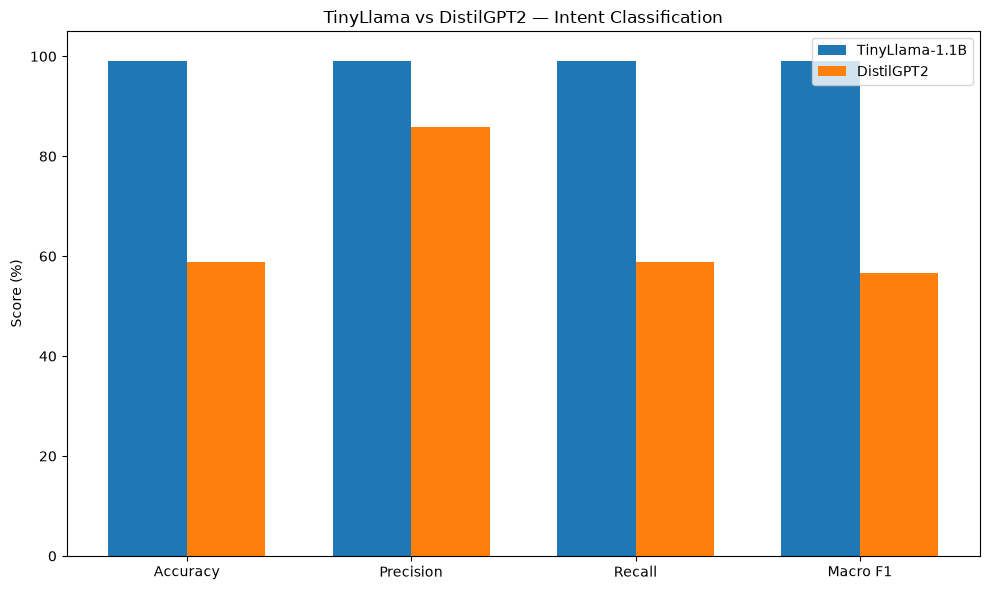

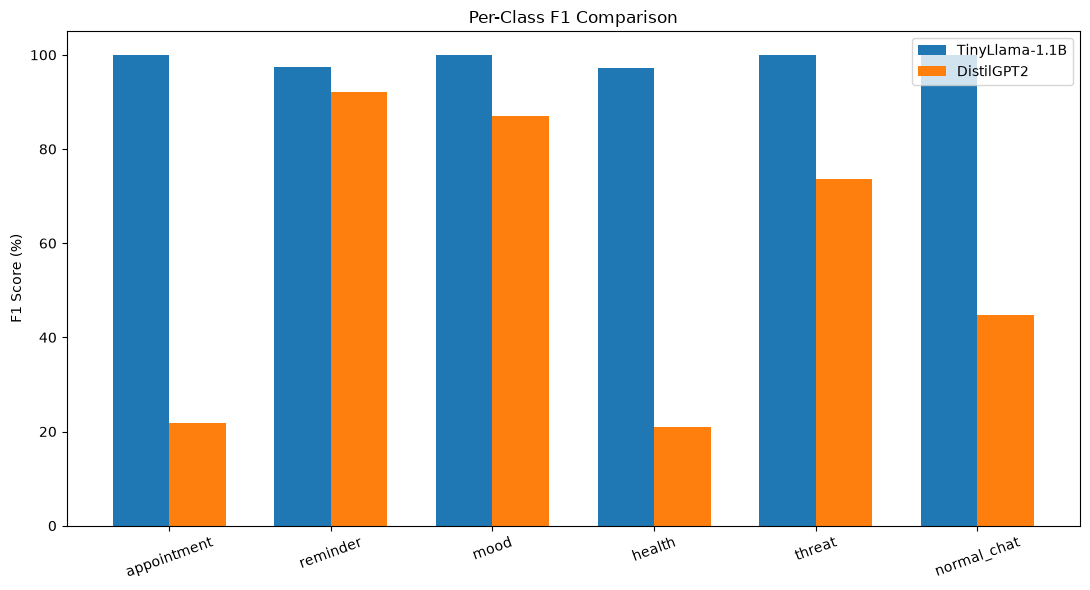

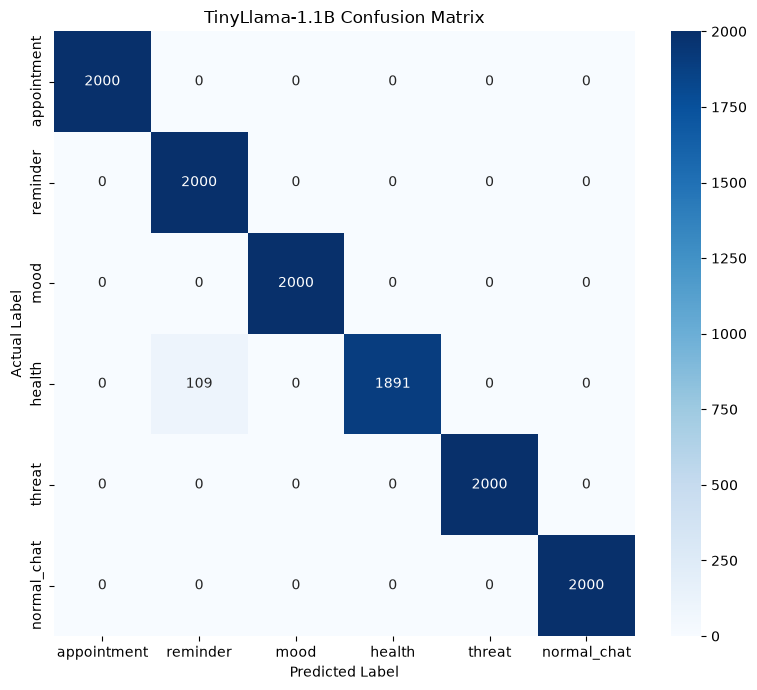

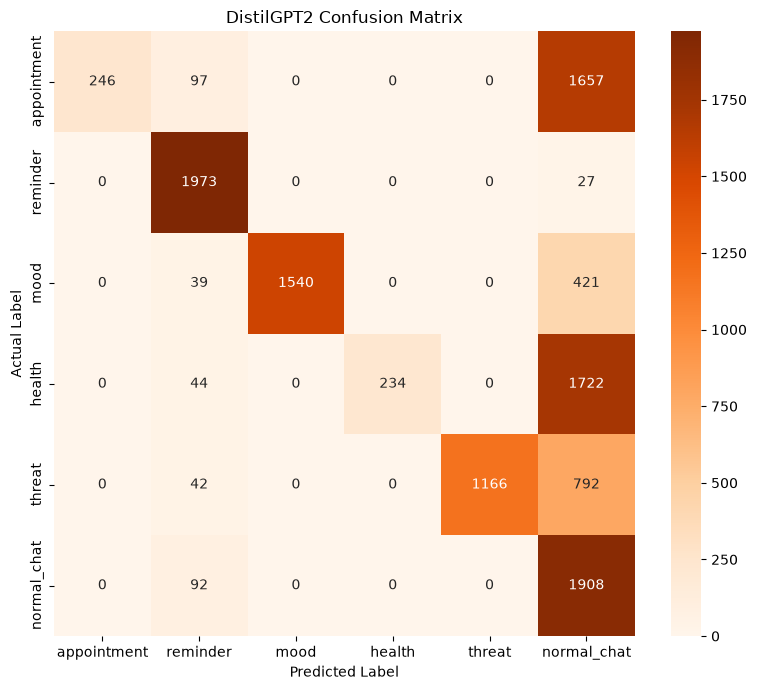

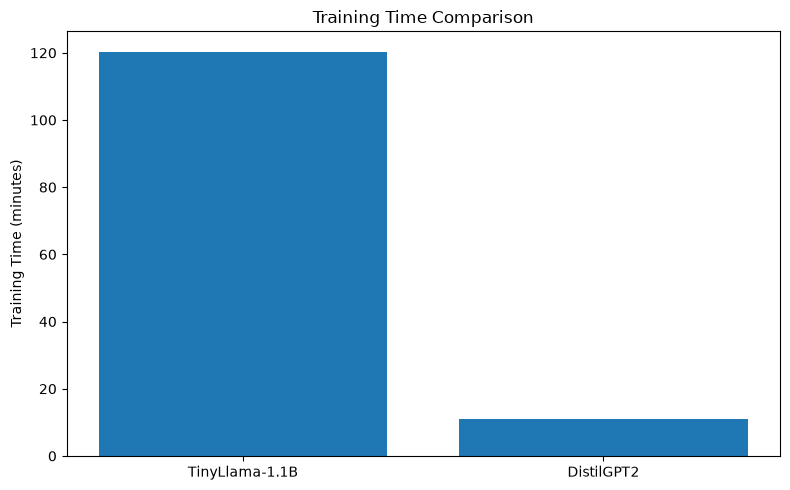

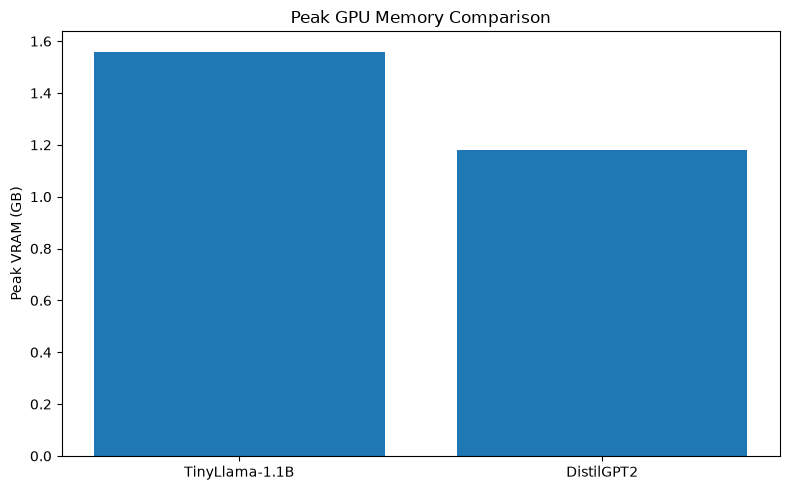


✓ COMPARISON COMPLETE

Saved:
/content/TinyLlama_vs_DistilGPT2_metrics.csv
/content/TinyLlama_vs_DistilGPT2_per_class_F1.csv
/content/TinyLlama_vs_DistilGPT2_resources.csv


In [12]:
# ============================================================
# PART 7 — TINYLLAMA vs DISTILGPT2
# FINAL MODEL COMPARISON
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Intent order
# ------------------------------------------------------------

INTENTS = [
    "appointment",
    "reminder",
    "mood",
    "health",
    "threat",
    "normal_chat"
]

# ------------------------------------------------------------
# 2. Load saved predictions
# ------------------------------------------------------------

TINY_FILE = (
    "/content/TinyLlama_FINAL_validation_predictions.csv"
)

DGPT_FILE = (
    "/content/DistilGPT2_FINAL_validation_predictions.csv"
)

tiny_df = pd.read_csv(TINY_FILE)
dgpt_df = pd.read_csv(DGPT_FILE)

assert len(tiny_df) == 12000
assert len(dgpt_df) == 12000

print("✓ TinyLlama predictions:", len(tiny_df))
print("✓ DistilGPT2 predictions:", len(dgpt_df))

# ------------------------------------------------------------
# 3. Calculate metrics
# ------------------------------------------------------------

def calculate_metrics(df):

    y_true = df["true_label"]
    y_pred = df["predicted_label"]

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=INTENTS,
            average="macro",
            zero_division=0
        )
    )

    return [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]


tiny_metrics = calculate_metrics(tiny_df)
dgpt_metrics = calculate_metrics(dgpt_df)

# ------------------------------------------------------------
# 4. Main comparison table
# ------------------------------------------------------------

comparison = pd.DataFrame(
    {
        "TinyLlama-1.1B": tiny_metrics,
        "DistilGPT2": dgpt_metrics
    },
    index=[
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1 (%)"
    ]
)

print("\n" + "=" * 65)
print("TINYLLAMA vs DISTILGPT2")
print("=" * 65)

print(
    comparison.round(2)
)

# ------------------------------------------------------------
# 5. Add experimental resource results
# ------------------------------------------------------------

resource_comparison = pd.DataFrame({

    "TinyLlama-1.1B": [
        120.38,
        1.56,
        1100000000
    ],

    "DistilGPT2": [
        11.09,
        1.18,
        82200000
    ]

}, index=[
    "Training Time (min)",
    "Peak VRAM (GB)",
    "Approx. Parameters"
])

print("\nResource Comparison")
print("-" * 65)

print(
    resource_comparison
)

# ------------------------------------------------------------
# 6. Per-class F1 comparison
# ------------------------------------------------------------

def class_f1(df):

    _, _, f1, _ = (
        precision_recall_fscore_support(
            df["true_label"],
            df["predicted_label"],
            labels=INTENTS,
            zero_division=0
        )
    )

    return f1 * 100


per_class = pd.DataFrame({

    "TinyLlama-1.1B": class_f1(tiny_df),

    "DistilGPT2": class_f1(dgpt_df)

}, index=INTENTS)

print("\nPer-Class F1 (%)")
print("-" * 65)

print(
    per_class.round(2)
)

# ------------------------------------------------------------
# 7. Accuracy / Precision / Recall / F1 graph
# ------------------------------------------------------------

metrics = [
    "Accuracy (%)",
    "Macro Precision (%)",
    "Macro Recall (%)",
    "Macro F1 (%)"
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    comparison.loc[metrics, "TinyLlama-1.1B"],
    width,
    label="TinyLlama-1.1B"
)

plt.bar(
    x + width/2,
    comparison.loc[metrics, "DistilGPT2"],
    width,
    label="DistilGPT2"
)

plt.xticks(x, [
    "Accuracy",
    "Precision",
    "Recall",
    "Macro F1"
])

plt.ylabel("Score (%)")
plt.ylim(0, 105)

plt.title(
    "TinyLlama vs DistilGPT2 — Intent Classification"
)

plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Per-class F1 graph
# ------------------------------------------------------------

x = np.arange(len(INTENTS))

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    per_class["TinyLlama-1.1B"],
    width,
    label="TinyLlama-1.1B"
)

plt.bar(
    x + width/2,
    per_class["DistilGPT2"],
    width,
    label="DistilGPT2"
)

plt.xticks(
    x,
    INTENTS,
    rotation=20
)

plt.ylabel("F1 Score (%)")
plt.ylim(0, 105)

plt.title(
    "Per-Class F1 Comparison"
)

plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. TinyLlama confusion matrix
# ------------------------------------------------------------

cm_tiny = confusion_matrix(
    tiny_df["true_label"],
    tiny_df["predicted_label"],
    labels=INTENTS
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm_tiny,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=INTENTS,
    yticklabels=INTENTS
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "TinyLlama-1.1B Confusion Matrix"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. DistilGPT2 confusion matrix
# ------------------------------------------------------------

cm_dgpt = confusion_matrix(
    dgpt_df["true_label"],
    dgpt_df["predicted_label"],
    labels=INTENTS
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    cm_dgpt,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=INTENTS,
    yticklabels=INTENTS
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title(
    "DistilGPT2 Confusion Matrix"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. Training time comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["TinyLlama-1.1B", "DistilGPT2"],
    [120.38, 11.09]
)

plt.ylabel("Training Time (minutes)")

plt.title(
    "Training Time Comparison"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. Peak VRAM comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    ["TinyLlama-1.1B", "DistilGPT2"],
    [1.56, 1.18]
)

plt.ylabel("Peak VRAM (GB)")

plt.title(
    "Peak GPU Memory Comparison"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. Save tables
# ------------------------------------------------------------

comparison.to_csv(
    "/content/TinyLlama_vs_DistilGPT2_metrics.csv"
)

per_class.to_csv(
    "/content/TinyLlama_vs_DistilGPT2_per_class_F1.csv"
)

resource_comparison.to_csv(
    "/content/TinyLlama_vs_DistilGPT2_resources.csv"
)

print("\n" + "=" * 65)
print("✓ COMPARISON COMPLETE")
print("=" * 65)

print("\nSaved:")
print("/content/TinyLlama_vs_DistilGPT2_metrics.csv")
print("/content/TinyLlama_vs_DistilGPT2_per_class_F1.csv")
print("/content/TinyLlama_vs_DistilGPT2_resources.csv")

# **PART 6 — TinyLlama Runtime, Latency & Resource Measurement**

In [14]:
# ============================================================
# PART 8 — TINYLLAMA RUNTIME PERFORMANCE
# Reloads SAVED checkpoint — NO RETRAINING
# ============================================================

import os
import time
import threading
import subprocess
import numpy as np
import pandas as pd
import psutil
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

# ------------------------------------------------------------
# 1. Saved TinyLlama checkpoint
# ------------------------------------------------------------

BASE_MODEL = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
ADAPTER_PATH = "/content/TinyLlama_ELDA_FINAL_epoch1"

print("Loading saved TinyLlama checkpoint...")

runtime_tokenizer = AutoTokenizer.from_pretrained(
    ADAPTER_PATH
)

runtime_tokenizer.padding_side = "left"

if runtime_tokenizer.pad_token is None:
    runtime_tokenizer.pad_token = (
        runtime_tokenizer.eos_token
    )

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16
)

base_model.config.pad_token_id = (
    runtime_tokenizer.pad_token_id
)

runtime_model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH
)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

runtime_model = runtime_model.to(device)
runtime_model.eval()

print("✓ TinyLlama loaded")
print("✓ Device:", device)

# ------------------------------------------------------------
# 2. Test configuration
# ------------------------------------------------------------

NUM_TESTS = 100
MAX_NEW_TOKENS = 5
MAX_LENGTH = 192

TEST_QUERIES = [
    "Remind me to take my medicine at 8 PM.",
    "I need to book an appointment with a doctor.",
    "I am feeling very sad today.",
    "I have a headache and feel weak.",
    "I think someone is following me.",
    "Can you tell me a joke?"
]

queries = [
    TEST_QUERIES[i % len(TEST_QUERIES)]
    for i in range(NUM_TESTS)
]

# ------------------------------------------------------------
# 3. Prompt
# ------------------------------------------------------------

def build_prompt(query):

    return (
        "Classify the following ELDA user request into exactly "
        "one label: appointment, reminder, mood, health, "
        "threat, normal_chat.\n"
        f"User: {query}\n"
        "Task:"
    )

# ------------------------------------------------------------
# 4. GPU monitor
# ------------------------------------------------------------

gpu_util_samples = []
monitoring = False

def monitor_gpu():

    global monitoring

    while monitoring:

        try:

            result = subprocess.check_output(
                [
                    "nvidia-smi",
                    "--query-gpu=utilization.gpu",
                    "--format=csv,noheader,nounits"
                ],
                stderr=subprocess.DEVNULL
            )

            value = float(
                result.decode()
                .strip()
                .split("\n")[0]
            )

            gpu_util_samples.append(value)

        except Exception:
            pass

        time.sleep(0.2)

# ------------------------------------------------------------
# 5. RAM monitoring
# ------------------------------------------------------------

process = psutil.Process(os.getpid())

ram_samples = []

# ------------------------------------------------------------
# 6. Warm-up
# ------------------------------------------------------------

print("\nRunning warm-up...")

warmup_prompt = build_prompt(
    TEST_QUERIES[0]
)

warmup_inputs = runtime_tokenizer(
    [warmup_prompt],
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH
)

warmup_inputs = {
    k: v.to(device)
    for k, v in warmup_inputs.items()
}

with torch.no_grad():

    _ = runtime_model.generate(
        **warmup_inputs,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False,
        num_beams=1,
        pad_token_id=runtime_tokenizer.pad_token_id,
        eos_token_id=runtime_tokenizer.eos_token_id
    )

if torch.cuda.is_available():

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

print("✓ Warm-up complete")

# ------------------------------------------------------------
# 7. Start monitoring
# ------------------------------------------------------------

monitoring = True

gpu_thread = threading.Thread(
    target=monitor_gpu,
    daemon=True
)

gpu_thread.start()

latencies = []

overall_start = time.perf_counter()

# ------------------------------------------------------------
# 8. Benchmark
# ------------------------------------------------------------

print("\nRunning TinyLlama runtime benchmark...")
print("Test requests:", NUM_TESTS)

for i, query in enumerate(queries):

    prompt = build_prompt(query)

    inputs = runtime_tokenizer(
        [prompt],
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        k: v.to(device)
        for k, v in inputs.items()
    }

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():

        _ = runtime_model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,
            num_beams=1,
            pad_token_id=runtime_tokenizer.pad_token_id,
            eos_token_id=runtime_tokenizer.eos_token_id
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.perf_counter()

    latency_ms = (
        end_time - start_time
    ) * 1000

    latencies.append(latency_ms)

    ram_used = (
        process.memory_info().rss
        / (1024 ** 3)
    )

    ram_samples.append(ram_used)

    if (i + 1) % 20 == 0:

        print(
            f"Processed {i + 1}/{NUM_TESTS}"
        )

overall_end = time.perf_counter()

# ------------------------------------------------------------
# 9. Stop monitoring
# ------------------------------------------------------------

monitoring = False
gpu_thread.join(timeout=1)

# ------------------------------------------------------------
# 10. Calculate results
# ------------------------------------------------------------

latencies = np.array(latencies)

average_latency = np.mean(latencies)
median_latency = np.median(latencies)
p95_latency = np.percentile(latencies, 95)
minimum_latency = np.min(latencies)
maximum_latency = np.max(latencies)

total_time = (
    overall_end - overall_start
)

throughput = (
    NUM_TESTS / total_time
)

peak_ram = max(ram_samples)

if gpu_util_samples:

    average_gpu = np.mean(
        gpu_util_samples
    )

    peak_gpu = np.max(
        gpu_util_samples
    )

else:

    average_gpu = np.nan
    peak_gpu = np.nan

if torch.cuda.is_available():

    peak_vram = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

else:

    peak_vram = np.nan

# ------------------------------------------------------------
# 11. Display
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("TINYLLAMA RUNTIME PERFORMANCE")
print("=" * 65)

print(
    f"Requests               : {NUM_TESTS}"
)

print(
    f"Average latency        : {average_latency:.2f} ms"
)

print(
    f"Median latency         : {median_latency:.2f} ms"
)

print(
    f"P95 latency            : {p95_latency:.2f} ms"
)

print(
    f"Minimum latency        : {minimum_latency:.2f} ms"
)

print(
    f"Maximum latency        : {maximum_latency:.2f} ms"
)

print(
    f"Throughput             : {throughput:.2f} req/s"
)

print(
    f"Peak RAM               : {peak_ram:.2f} GB"
)

print(
    f"Peak VRAM              : {peak_vram:.2f} GB"
)

print(
    f"Average GPU utilisation: "
    f"{average_gpu:.2f}%"
)

print(
    f"Peak GPU utilisation   : "
    f"{peak_gpu:.2f}%"
)

# ------------------------------------------------------------
# 12. Save latency measurements
# ------------------------------------------------------------

latency_df = pd.DataFrame({
    "test_id": range(1, NUM_TESTS + 1),
    "query": queries,
    "latency_ms": latencies
})

latency_file = (
    "/content/ELDA_TinyLlama_latency_measurements.csv"
)

latency_df.to_csv(
    latency_file,
    index=False
)

# ------------------------------------------------------------
# 13. Save summary
# ------------------------------------------------------------

summary_df = pd.DataFrame({

    "Metric": [
        "Number of requests",
        "Average latency (ms)",
        "Median latency (ms)",
        "P95 latency (ms)",
        "Minimum latency (ms)",
        "Maximum latency (ms)",
        "Throughput (requests/sec)",
        "Peak RAM (GB)",
        "Peak VRAM (GB)",
        "Average GPU utilisation (%)",
        "Peak GPU utilisation (%)"
    ],

    "Value": [
        NUM_TESTS,
        average_latency,
        median_latency,
        p95_latency,
        minimum_latency,
        maximum_latency,
        throughput,
        peak_ram,
        peak_vram,
        average_gpu,
        peak_gpu
    ]
})

summary_file = (
    "/content/ELDA_TinyLlama_runtime_summary.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

print("\n✓ Latency measurements saved:")
print(latency_file)

print("\n✓ Runtime summary saved:")
print(summary_file)

print("\n✓ PART 8 COMPLETE")

Loading saved TinyLlama checkpoint...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✓ TinyLlama loaded
✓ Device: cuda

Running warm-up...


[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


✓ Warm-up complete

Running TinyLlama runtime benchmark...
Test requests: 100


... (6 outputs left out)

[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Processed 80/100


[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Processed 100/100

TINYLLAMA RUNTIME PERFORMANCE
Requests               : 100
Average latency        : 291.88 ms
Median latency         : 265.82 ms
P95 latency            : 417.04 ms
Minimum latency        : 247.46 ms
Maximum latency        : 642.75 ms
Throughput             : 3.42 req/s
Peak RAM               : 4.49 GB
Peak VRAM              : 3.35 GB
Average GPU utilisation: 35.13%
Peak GPU utilisation   : 45.00%

✓ Latency measurements saved:
/content/ELDA_TinyLlama_latency_measurements.csv

✓ Runtime summary saved:
/content/ELDA_TinyLlama_runtime_summary.csv

✓ PART 8 COMPLETE


# **Part 7 : Emotion Conditioned Response Layer**

In [15]:
# ============================================================
# PART 9A — CHECK EMOTION DATA
# ============================================================

import pandas as pd

TRAIN_FILE = "/content/ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv"
VAL_FILE   = "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"

train_check = pd.read_csv(TRAIN_FILE)
val_check = pd.read_csv(VAL_FILE)

print("TRAINING COLUMNS:")
print(train_check.columns.tolist())

print("\nVALIDATION COLUMNS:")
print(val_check.columns.tolist())

print("\nTRAINING SHAPE:")
print(train_check.shape)

print("\nVALIDATION SHAPE:")
print(val_check.shape)

# Check possible emotion-related columns
emotion_columns = [
    c for c in train_check.columns
    if any(
        word in c.lower()
        for word in [
            "emotion",
            "mood",
            "sentiment",
            "feeling"
        ]
    )
]

print("\nPossible emotion columns:")
print(emotion_columns)

for col in emotion_columns:

    print("\n" + "=" * 50)
    print("Column:", col)
    print("=" * 50)

    print(
        train_check[col]
        .value_counts(dropna=False)
        .head(20)
    )

TRAINING COLUMNS:
['id', 'user_query', 'response', 'task']

VALIDATION COLUMNS:
['id', 'user_query', 'response', 'task']

TRAINING SHAPE:
(48000, 4)

VALIDATION SHAPE:
(12000, 4)

Possible emotion columns:
[]


# **Part 8 : HCWIF SOS Fusion Experiment**

In [16]:
# ============================================================
# PART 10A — INSPECT SOS DATA
# ============================================================

import pandas as pd
import os

print("CSV files in /content:\n")

for f in os.listdir("/content"):
    if f.lower().endswith(".csv"):
        print(f)

print("\n" + "=" * 60)
print("CHECKING CURRENT VALIDATION DATA")
print("=" * 60)

val = pd.read_csv(
    "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"
)

print("\nColumns:")
print(val.columns.tolist())

print("\nTask distribution:")
print(val["task"].value_counts())

print("\nThreat examples:")
print(
    val[val["task"] == "threat"]
    [["user_query", "response"]]
    .head(10)
    .to_string(index=False)
)

CSV files in /content:

TinyLlama_FINAL_validation_predictions.csv
ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv
ELDA_TinyLlama_runtime_summary.csv
ELDA_TinyLlama_latency_measurements.csv
ELDA_TRAINING_48000_LEAK_SAFE_EXACT80.csv
TinyLlama_vs_DistilGPT2_per_class_F1.csv
Qwen25_05B_FINAL_validation_predictions.csv
DistilGPT2_FINAL_validation_predictions.csv
TinyLlama_vs_DistilGPT2_resources.csv
TinyLlama_vs_DistilGPT2_metrics.csv

CHECKING CURRENT VALIDATION DATA

Columns:
['id', 'user_query', 'response', 'task']

Task distribution:
task
mood           2000
health         2000
appointment    2000
normal_chat    2000
threat         2000
reminder       2000
Name: count, dtype: int64

Threat examples:
                                                                              user_query                                                                                                            response
      I need immediate support because i do not feel safe and I need someone to talk to.  

# **Build HCWIF features + four SOS methods**

In [17]:
# ============================================================
# PART 10B — HCWIF SOS ABLATION
# Text-based experimental evaluation
# ============================================================

import re
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Load validation data + TinyLlama predictions
# ------------------------------------------------------------

VAL_FILE = (
    "/content/ELDA_VALIDATION_12000_LEAK_SAFE_EXACT20.csv"
)

TINY_FILE = (
    "/content/TinyLlama_FINAL_validation_predictions.csv"
)

df = pd.read_csv(VAL_FILE)
tiny = pd.read_csv(TINY_FILE)

assert len(df) == 12000
assert len(tiny) == 12000

# Keep original ordering
df["tiny_prediction"] = tiny["predicted_label"].values

# Ground truth: threat = SOS
df["true_sos"] = (
    df["task"].astype(str).str.lower() == "threat"
).astype(int)

print("Total samples:", len(df))
print("SOS samples:", df["true_sos"].sum())
print("Non-SOS samples:", len(df) - df["true_sos"].sum())


# ------------------------------------------------------------
# 2. Text-based SOS evidence
# ------------------------------------------------------------

SOS_TERMS = [
    "not safe",
    "unsafe",
    "immediate support",
    "need help",
    "emergency",
    "hurt myself",
    "hurt someone",
    "harm myself",
    "harm someone",
    "lose control",
    "violent",
    "danger",
    "dangerous",
    "urgent",
    "afraid i might",
    "scared",
    "help me"
]

def keyword_score(text):

    text = str(text).lower()

    matches = sum(
        1 for term in SOS_TERMS
        if term in text
    )

    # Normalize to 0-1
    return min(
        matches / 3.0,
        1.0
    )


# ------------------------------------------------------------
# 3. Distress-language score
# ------------------------------------------------------------

DISTRESS_TERMS = [
    "scared",
    "afraid",
    "frightened",
    "terrified",
    "helpless",
    "panic",
    "worried",
    "desperate",
    "unsafe",
    "danger",
    "emergency",
    "lose control"
]

def distress_score(text):

    text = str(text).lower()

    matches = sum(
        1 for term in DISTRESS_TERMS
        if term in text
    )

    return min(
        matches / 3.0,
        1.0
    )


# ------------------------------------------------------------
# 4. TinyLlama intent signal
# ------------------------------------------------------------

def intent_score(prediction):

    return int(
        str(prediction).lower() == "threat"
    )


df["keyword_score"] = (
    df["user_query"]
    .apply(keyword_score)
)

df["distress_score"] = (
    df["user_query"]
    .apply(distress_score)
)

df["intent_score"] = (
    df["tiny_prediction"]
    .apply(intent_score)
)

print("\nFeature extraction complete.")

print(
    df[
        [
            "keyword_score",
            "distress_score",
            "intent_score"
        ]
    ].describe()
)


# ------------------------------------------------------------
# 5. Feature matrix
# ------------------------------------------------------------

X = df[
    [
        "keyword_score",
        "intent_score",
        "distress_score"
    ]
].values

y = df["true_sos"].values


# ------------------------------------------------------------
# 6. Method A — Current rule-based SOS
# ------------------------------------------------------------

# Rule:
# trigger SOS if at least one strong keyword signal exists.

rule_score = df["keyword_score"].values

pred_rule = (
    rule_score >= 0.3333
).astype(int)


# ------------------------------------------------------------
# 7. Method B — Equal-weight fusion
# ------------------------------------------------------------

equal_score = (
    df["keyword_score"].values
    + df["intent_score"].values
    + df["distress_score"].values
) / 3.0

pred_equal = (
    equal_score >= 0.50
).astype(int)


# ------------------------------------------------------------
# 8. Method C — HCWIF fixed weights
# ------------------------------------------------------------

# Fixed weights:
# keyword evidence = 0.40
# intent evidence  = 0.40
# distress evidence = 0.20

HCWIF_WEIGHTS = {
    "keyword": 0.40,
    "intent": 0.40,
    "distress": 0.20
}

hcwif_score = (
    HCWIF_WEIGHTS["keyword"]
    * df["keyword_score"].values
    +
    HCWIF_WEIGHTS["intent"]
    * df["intent_score"].values
    +
    HCWIF_WEIGHTS["distress"]
    * df["distress_score"].values
)

pred_hcwif = (
    hcwif_score >= 0.50
).astype(int)


# ------------------------------------------------------------
# 9. Method D — Learned logistic regression
# ------------------------------------------------------------

# IMPORTANT:
# We do not train and test on the same records.
# 60% is used to learn fusion weights.
# 40% is held out for evaluation.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

fusion_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

fusion_model.fit(
    X_train,
    y_train
)

logistic_prob = fusion_model.predict_proba(
    X_test
)[:, 1]

pred_logistic = (
    logistic_prob >= 0.50
).astype(int)


# ------------------------------------------------------------
# 10. Evaluation function
# ------------------------------------------------------------

def evaluate_sos(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    false_alarm_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "Specificity": specificity,
        "F1": f1,
        "False Alarm Rate": false_alarm_rate,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }


# ------------------------------------------------------------
# 11. Evaluate common held-out test set
# ------------------------------------------------------------

# To make the comparison fair, evaluate all methods
# on the SAME held-out 40% records.

# Recover the test indices using the same split.

indices = np.arange(len(df))

idx_train, idx_test = train_test_split(
    indices,
    test_size=0.40,
    random_state=42,
    stratify=y
)

y_common = y[idx_test]

results = {}

results["Rule-based SOS"] = evaluate_sos(
    y_common,
    pred_rule[idx_test]
)

results["Equal-weight Fusion"] = evaluate_sos(
    y_common,
    pred_equal[idx_test]
)

results["HCWIF Fixed Weights"] = evaluate_sos(
    y_common,
    pred_hcwif[idx_test]
)

results["Logistic Regression Fusion"] = evaluate_sos(
    y_test,
    pred_logistic
)


# ------------------------------------------------------------
# 12. Results table
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
).T

print("\n" + "=" * 75)
print("HCWIF SOS ABLATION RESULTS")
print("=" * 75)

print(
    results_df[
        [
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "False Alarm Rate"
        ]
    ].round(4)
)


# ------------------------------------------------------------
# 13. HCWIF learned coefficients
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("LOGISTIC REGRESSION LEARNED WEIGHTS")
print("=" * 75)

coef_df = pd.DataFrame({
    "Feature": [
        "Keyword evidence",
        "TinyLlama threat intent",
        "Distress evidence"
    ],
    "Coefficient": fusion_model.coef_[0]
})

print(
    coef_df.round(4)
)


# ------------------------------------------------------------
# 14. Save results
# ------------------------------------------------------------

RESULT_FILE = (
    "/content/ELDA_HCWIF_ablation_results.csv"
)

results_df.to_csv(
    RESULT_FILE
)

COEF_FILE = (
    "/content/ELDA_HCWIF_learned_weights.csv"
)

coef_df.to_csv(
    COEF_FILE,
    index=False
)

FEATURE_FILE = (
    "/content/ELDA_HCWIF_features.csv"
)

df[
    [
        "id",
        "user_query",
        "task",
        "true_sos",
        "tiny_prediction",
        "keyword_score",
        "intent_score",
        "distress_score"
    ]
].to_csv(
    FEATURE_FILE,
    index=False
)

print("\n✓ Results saved:")
print(RESULT_FILE)

print("\n✓ Learned weights saved:")
print(COEF_FILE)

print("\n✓ HCWIF features saved:")
print(FEATURE_FILE)

print("\n✓ PART 10B COMPLETE")

Total samples: 12000
SOS samples: 2000
Non-SOS samples: 10000

Feature extraction complete.
       keyword_score  distress_score  intent_score
count   12000.000000    12000.000000  12000.000000
mean        0.105667        0.042222      0.166667
std         0.234612        0.127788      0.372694
min         0.000000        0.000000      0.000000
25%         0.000000        0.000000      0.000000
50%         0.000000        0.000000      0.000000
75%         0.000000        0.000000      0.000000
max         1.000000        0.666667      1.000000

HCWIF SOS ABLATION RESULTS
                            Precision  Recall  Specificity      F1  \
Rule-based SOS                 0.6875  0.8388       0.9238  0.7556   
Equal-weight Fusion            1.0000  0.6438       1.0000  0.7833   
HCWIF Fixed Weights            1.0000  0.8388       1.0000  0.9123   
Logistic Regression Fusion     1.0000  1.0000       1.0000  1.0000   

                            False Alarm Rate  
Rule-based SOS         

# **Actual SOS Detection Latency**

In [18]:
# ============================================================
# PART 10C — SOS DETECTION LATENCY
# ============================================================

import time
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Load the HCWIF feature file
# ------------------------------------------------------------

FEATURE_FILE = "/content/ELDA_HCWIF_features.csv"

hcwif_df = pd.read_csv(FEATURE_FILE)

print("Samples:", len(hcwif_df))

# ------------------------------------------------------------
# 2. Feature arrays
# ------------------------------------------------------------

K = hcwif_df["keyword_score"].values
I = hcwif_df["intent_score"].values
D = hcwif_df["distress_score"].values

# ------------------------------------------------------------
# 3. Timing functions
# ------------------------------------------------------------

def measure_latency(function, repetitions=100):

    latencies = []

    for _ in range(repetitions):

        start = time.perf_counter()

        function()

        end = time.perf_counter()

        latencies.append(
            (end - start) * 1000
        )

    return np.array(latencies)


# ------------------------------------------------------------
# 4. Define SOS decisions
# ------------------------------------------------------------

def rule_based():

    return (
        K >= 0.3333
    ).astype(int)


def equal_weight():

    score = (
        K + I + D
    ) / 3.0

    return (
        score >= 0.50
    ).astype(int)


def hcwif_fixed():

    score = (
        0.40 * K
        + 0.40 * I
        + 0.20 * D
    )

    return (
        score >= 0.50
    ).astype(int)


def logistic_fusion():

    X = np.column_stack([
        K,
        I,
        D
    ])

    return fusion_model.predict(
        X
    )


# ------------------------------------------------------------
# 5. Measure latency
# ------------------------------------------------------------

print("\nMeasuring SOS decision latency...")

rule_times = measure_latency(
    rule_based
)

equal_times = measure_latency(
    equal_weight
)

hcwif_times = measure_latency(
    hcwif_fixed
)

logistic_times = measure_latency(
    logistic_fusion
)

# ------------------------------------------------------------
# 6. Summary function
# ------------------------------------------------------------

def latency_summary(times):

    return {
        "Mean latency (ms)": np.mean(times),
        "Median latency (ms)": np.median(times),
        "P95 latency (ms)": np.percentile(
            times,
            95
        ),
        "Minimum latency (ms)": np.min(times),
        "Maximum latency (ms)": np.max(times)
    }


latency_results = pd.DataFrame({

    "Rule-based SOS":
        latency_summary(rule_times),

    "Equal-weight Fusion":
        latency_summary(equal_times),

    "HCWIF Fixed Weights":
        latency_summary(hcwif_times),

    "Logistic Regression Fusion":
        latency_summary(logistic_times)

}).T

# ------------------------------------------------------------
# 7. Display results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SOS DETECTION LATENCY RESULTS")
print("=" * 75)

print(
    latency_results.round(4)
)

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

LATENCY_FILE = (
    "/content/ELDA_HCWIF_detection_latency.csv"
)

latency_results.to_csv(
    LATENCY_FILE
)

print("\n✓ Saved:")
print(LATENCY_FILE)

print("\n✓ PART 10C COMPLETE")

Samples: 12000

Measuring SOS decision latency...

SOS DETECTION LATENCY RESULTS
                            Mean latency (ms)  Median latency (ms)  \
Rule-based SOS                         0.0375               0.0113   
Equal-weight Fusion                    0.1516               0.0551   
HCWIF Fixed Weights                    0.1642               0.0804   
Logistic Regression Fusion             2.1502               0.5853   

                            P95 latency (ms)  Minimum latency (ms)  \
Rule-based SOS                        0.0349                0.0098   
Equal-weight Fusion                   0.4948                0.0480   
HCWIF Fixed Weights                   0.4131                0.0609   
Logistic Regression Fusion            8.6105                0.4553   

                            Maximum latency (ms)  
Rule-based SOS                            1.1389  
Equal-weight Fusion                       3.1457  
HCWIF Fixed Weights                       1.3255  
Logistic Regr

# **Final HCIF Plot**

FINAL HCWIF RESULTS
                            Precision  Recall  Specificity      F1  \
Rule-based SOS                 0.6875  0.8388       0.9238  0.7556   
Equal-weight Fusion            1.0000  0.6438       1.0000  0.7833   
HCWIF Fixed Weights            1.0000  0.8388       1.0000  0.9123   
Logistic Regression Fusion     1.0000  1.0000       1.0000  1.0000   

                            False Alarm Rate  
Rule-based SOS                        0.0762  
Equal-weight Fusion                   0.0000  
HCWIF Fixed Weights                   0.0000  
Logistic Regression Fusion            0.0000  


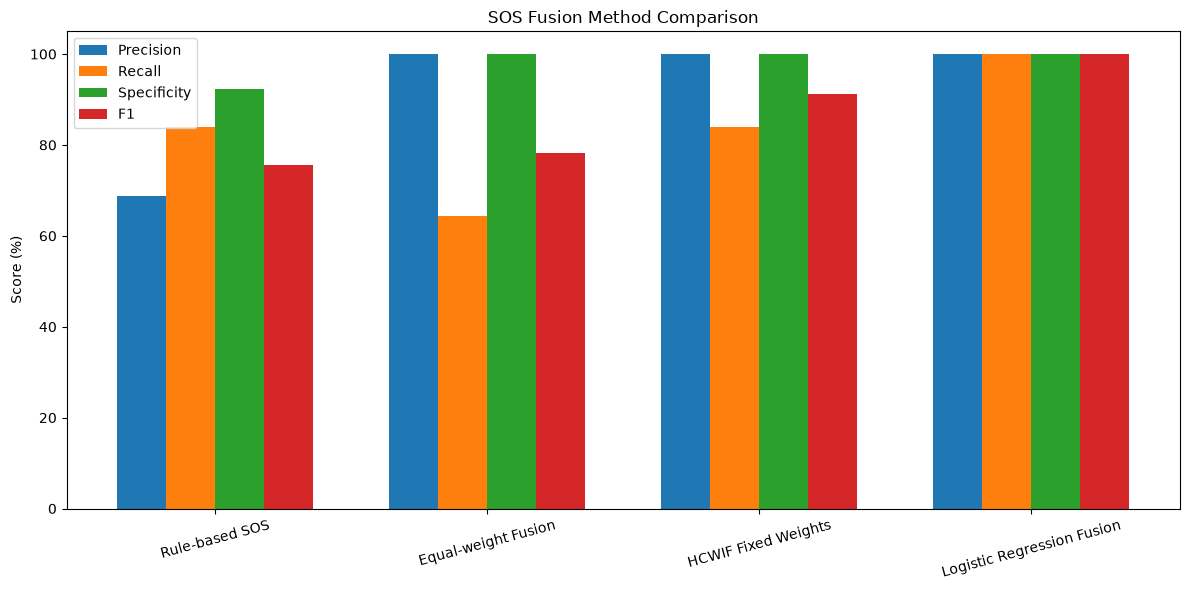

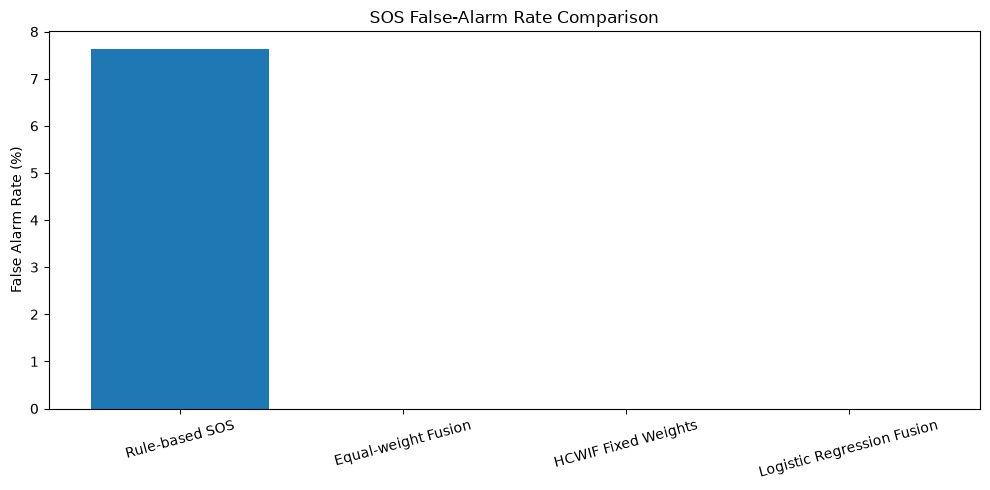

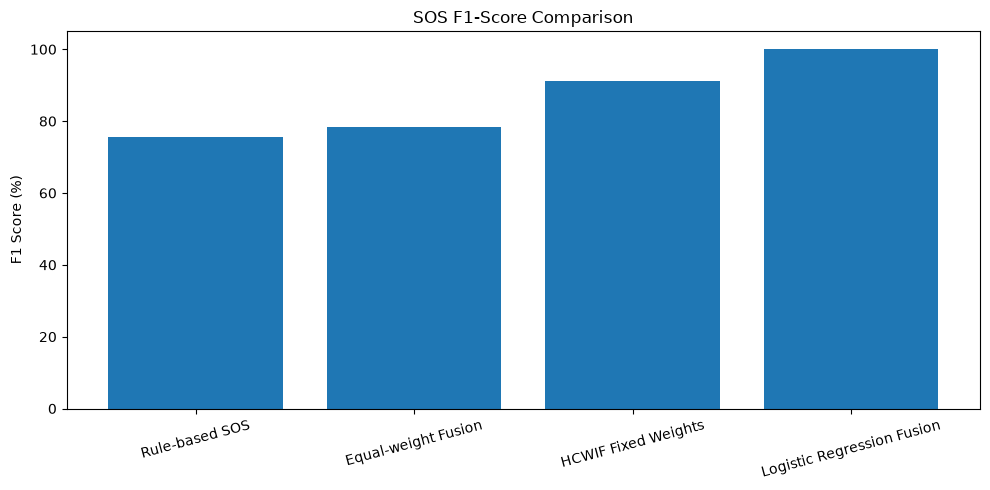

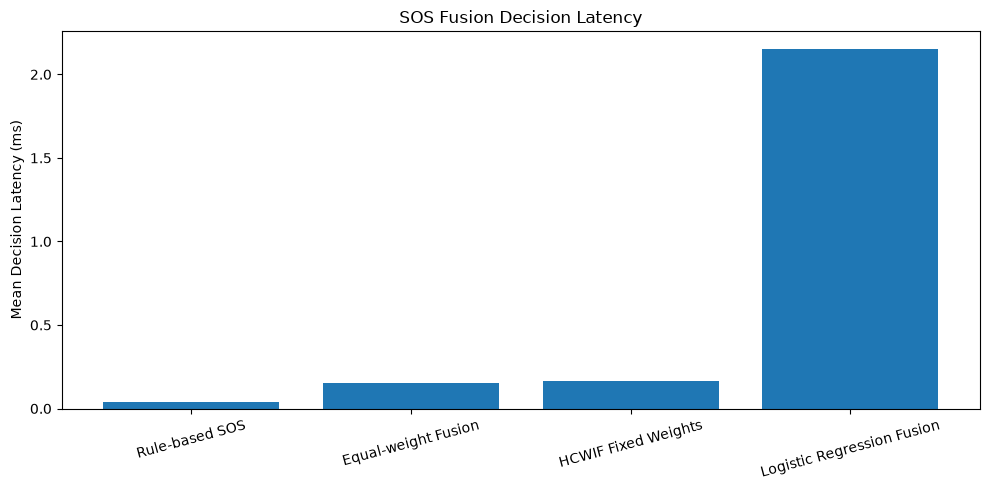


PAPER-READY HCWIF TABLE
                            Precision  Recall  Specificity      F1  \
Rule-based SOS                  68.75   83.88        92.38   75.56   
Equal-weight Fusion            100.00   64.38       100.00   78.33   
HCWIF Fixed Weights            100.00   83.88       100.00   91.23   
Logistic Regression Fusion     100.00  100.00       100.00  100.00   

                            False Alarm Rate  Mean Latency (ms)  \
Rule-based SOS                          7.62               0.04   
Equal-weight Fusion                     0.00               0.15   
HCWIF Fixed Weights                     0.00               0.16   
Logistic Regression Fusion              0.00               2.15   

                            P95 Latency (ms)  
Rule-based SOS                          0.03  
Equal-weight Fusion                     0.49  
HCWIF Fixed Weights                     0.41  
Logistic Regression Fusion              8.61  

✓ Final HCWIF table saved:
/content/ELDA_HCWIF_FINAL

In [19]:
# ============================================================
# PART 10D — FINAL HCWIF FIGURES + RESULTS TABLE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load saved results
# ------------------------------------------------------------

RESULT_FILE = "/content/ELDA_HCWIF_ablation_results.csv"
LATENCY_FILE = "/content/ELDA_HCWIF_detection_latency.csv"

results = pd.read_csv(
    RESULT_FILE,
    index_col=0
)

latency = pd.read_csv(
    LATENCY_FILE,
    index_col=0
)

methods = results.index.tolist()

print("=" * 70)
print("FINAL HCWIF RESULTS")
print("=" * 70)

print(
    results[
        [
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "False Alarm Rate"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 2. Convert to percentage for plotting
# ------------------------------------------------------------

plot_metrics = results[
    [
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "False Alarm Rate"
    ]
].copy()

plot_metrics = plot_metrics * 100

# ------------------------------------------------------------
# 3. Main performance comparison
# ------------------------------------------------------------

x = np.arange(len(methods))
width = 0.18

plt.figure(figsize=(12, 6))

for i, metric in enumerate(
    ["Precision", "Recall", "Specificity", "F1"]
):

    plt.bar(
        x + (i - 1.5) * width,
        plot_metrics[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    methods,
    rotation=15
)

plt.ylabel("Score (%)")
plt.ylim(0, 105)

plt.title(
    "SOS Fusion Method Comparison"
)

plt.legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. False-alarm rate
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    methods,
    plot_metrics["False Alarm Rate"]
)

plt.ylabel("False Alarm Rate (%)")

plt.title(
    "SOS False-Alarm Rate Comparison"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. F1 comparison
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    methods,
    plot_metrics["F1"]
)

plt.ylabel("F1 Score (%)")
plt.ylim(0, 105)

plt.title(
    "SOS F1-Score Comparison"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Fusion latency comparison
# ------------------------------------------------------------

mean_latency = latency[
    "Mean latency (ms)"
]

plt.figure(figsize=(10, 5))

plt.bar(
    mean_latency.index,
    mean_latency.values
)

plt.ylabel("Mean Decision Latency (ms)")

plt.title(
    "SOS Fusion Decision Latency"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Final paper table
# ------------------------------------------------------------

paper_table = results[
    [
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "False Alarm Rate"
    ]
].copy()

paper_table = paper_table * 100

paper_table["Mean Latency (ms)"] = (
    latency["Mean latency (ms)"]
)

paper_table["P95 Latency (ms)"] = (
    latency["P95 latency (ms)"]
)

print("\n" + "=" * 90)
print("PAPER-READY HCWIF TABLE")
print("=" * 90)

print(
    paper_table.round(2)
)

# ------------------------------------------------------------
# 8. Save final table
# ------------------------------------------------------------

FINAL_FILE = (
    "/content/ELDA_HCWIF_FINAL_RESULTS.csv"
)

paper_table.to_csv(
    FINAL_FILE
)

print("\n✓ Final HCWIF table saved:")
print(FINAL_FILE)

print("\n✓ PART 10D COMPLETE")